# calibrate_1q's frequency and amplitude ladders

## Overview

calibrate_1q rarely rejects a value, but its rejections pile up on a few qubits ([Phase 01, B2](../../docs/phases/01_eda.md#b2-ds2-hardware-models)). Before a warning can be read as a device event, it needs a clear meaning. This notebook asks two questions about the frequency and amplitude ladders: what a warning is when it fires, and whether the error the routine leaves behind costs the gates anything.

**Hypothesis.** Most frequency and amplitude warnings come from the routine's own rules, not from the qubits. The error the routine leaves behind costs the 1q gates little, whether it runs twice a day or less often. If so, calibration work has more room in the DRAG step, readout and the 2q gates.

**Method.**

- Decode the raw Ramsey and FineFrequency payloads and check that they reproduce every warning and applied value (section 1).
- Sort the frequency warnings into classes and compare each class's values with the next run (section 2).
- Explain the bias of the 0.1 µs step with a pulse phase plus the pulse width (section 3).
- Test whether frequency offsets cost 1q RB like a real detuning (section 4).
- Price the error the amplitude ladder leaves when it stops short (section 5).
- Split the 1q infidelity into parts, check the coherence part with Ramsey T2\*, and set it next to readout and the 2q gates (section 6).
- Price what running calibrate_1q less often would cost (section 7).
- Replay fixed rules for the applied frequency on warned runs (section 8).

> **The benchmarks run just after a calibration.** The daily benchmark starts about 30 minutes after the evening calibrate_1q run (section 4). So DS3 can price the error a run leaves behind, but not the drift between calibrations. Section 7 uses a cost model for that instead.

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import decode, periods
from qpu_drift.analysis import series
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_runs_l2
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH
from qpu_drift.sources.hardware_models import load_values
from qpu_drift.sources.measurements import load_measurements, local_payloads

pd.set_option(
    "display.max_rows",
    200,
    "display.max_columns",
    30,
    "display.width",
    250,
    "display.max_colwidth",
    120,
)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

# Frequency ladder
STEP = {1e-7: 1, 2.5e-7: 2, 5e-7: 3}  # FineFrequency delay -> ladder step
TAU = {s: d for d, s in STEP.items()}
MAX_GAP = pd.Timedelta("1.5D")  # the next run is a usable reference within this gap

# Step 2 "echoes" step 1 when |d1 + d2| < max(ECHO_ABS, ECHO_REL |d1|)
ECHO_ABS, ECHO_REL = 100e3, 0.3

LOW_CONTRAST = 0.5  # trace amplitude below this share of the qubit's median
POOR_FIT = 3.0  # Ramsey residual rms / shot noise above this multiple of the qubit's median
BIG = 200e3  # a large set-point error (Hz)
LADDER3 = pd.Timestamp("2025-03-28")  # the three-step ladder runs from here on

# Eras: 2024 | 2025-26Q1 | 2026Q2+ (from the thermal cycle)
ERA_EDGES = pd.to_datetime(["2025-01-01", "2026-03-09"])
ERAS = ["2024", "2025-26Q1", "2026Q2+"]
EXCL = [i.period for i in periods.INCIDENTS] + list(periods.SETTLING)

# Benchmark linkage and cost tests.
# A benchmark is linked to the calibrate_1q run at most MAX_LAG before it.
MAX_LAG = pd.Timedelta("2h")
MAX_E = 2e6  # Hz: a larger applied - Ramsey offset means the Ramsey fit failed

# Within-qubit controls: |e| < 25 kHz within +-7 days, at least 3 of them
CTRL, WIN, MIN_CTRL = 25e3, pd.Timedelta("7D"), 3

BINS = [25e3, 50e3, 100e3, 200e3, 400e3, np.inf]
LABELS = ["25-50", "50-100", "100-200", "200-400", ">=400"]
MIN_RUNS = 20  # calibration runs per qubit-quarter for a phase estimate
MIN_CELL = 10  # kept fRB rows per qubit-quarter for within-cell tests
A_GRID = np.round(np.arange(-0.5, 1.5001, 0.05), 2)

# Amplitude ladder
AMP_FROM = pd.Timestamp("2025-01-01")  # N = 1, 2, 4, 8 throughout; DS3 KPIs well covered
BETA = 1.9  # X/2 pulses per Clifford
AMP_BIG = 0.02  # |ε| above this is a large residual

# End of settling after the thermal cycle: the current cooldown for section 6
COOL = periods.SETTLING[0][1]

# Recalibration cadence (section 7)
LAGS = [1, 2, 3, 4, 6, 8, 14, 28]  # in calibrate_1q writes per qubit
STOP = {"BREAK", "OUTAGE", "THERMAL_CYCLE", "INCIDENT"}  # pairs of writes across these are left out
CUT_KHZ = 2000  # a larger frequency change between writes is a failed Ramsey fit, not drift (as MAX_E)
AMP_CUT = 0.1  # a larger amp x scale change is beyond the N = 1 window, so not a ladder result

# DS2 paths for the drive frequency, X/2 amplitude and X/2 width (capture group: the qubit)
PATHS = {
    "freq": r"model\.pulse_channels\{Ch\d+\.Q(\d+)\.drive\}\.pulse_channel\.frequency",
    "amp": r"model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{amp\}",
    "width": r"model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{width\}",
}

N_BOOT = 1000
rng = np.random.default_rng(0)

def era(t):
    """Era label for each timestamp in t."""
    return pd.Series(
        np.select([t < ERA_EDGES[0], t < ERA_EDGES[1]], ERAS[:2], ERAS[2]), index=t.index
    )

def khz(v, q=0.5):
    """Quantile q of |v|, in kHz to one decimal."""
    return round(float(np.nanquantile(np.abs(v), q)) / 1e3, 1)

# KPI rows, and the kept rows (B4)
kpi = pd.read_parquet(KPI_SUPPLEMENTED_PATH)
k = series.kpi_rows(kpi, load_runs_l2())
k["t"] = k["t"].astype("datetime64[ns]")
kept = series.kept_kpi(k)
print(
    f"KPI rows {len(k):,}, kept {len(kept):,}, runs {k['run'].nunique():,}, "
    f"{k['t'].min():%Y-%m-%d} to {k['t'].max():%Y-%m-%d}"
)

# Valid calibrate_1q runs, and where each measurement payload sits on disk
rr = load_run_results()
rr1 = rr[(rr["routine"] == "calibrate_1q") & rr["valid"]]
meas = load_measurements()[["id", "relative_filepath"]]
paths = local_payloads()

def payload_ids(steps):
    """One row per payload of the given steps, with its local path (NaN if missing)."""
    ids = rr1[rr1["step"].isin(steps)].drop_duplicates("result_id")
    ids = ids[["start", "step", "result_id"]]
    ids = ids.merge(meas, left_on="result_id", right_on="id", how="left")
    ids["path"] = ids["relative_filepath"].map(paths)
    return ids

v = load_values()

def ds2(pat, name):
    """DS2 value history for a per-qubit path pattern with one capture group (the qubit)."""
    d = v[v["path"].str.match(pat)].copy()
    d["qubit"] = d["path"].str.extract(pat, expand=False).astype(int)
    d[name] = d["value_float"].fillna(d["value_int"])
    d = d.sort_values("valid_from_ts").astype(
        {"valid_from_ts": "datetime64[ns]", "valid_to_ts": "datetime64[ns]"}
    )
    return d[["qubit", "valid_from_ts", "valid_to_ts", name]].drop_duplicates(
        ["qubit", "valid_from_ts"], keep="last"
    )

def at_time(x, d, tcol):
    """Attach the DS2 value in effect at x[tcol] (NaN outside any validity interval)."""
    name = d.columns[-1]
    x = pd.merge_asof(
        x.sort_values(tcol),
        d,
        left_on=tcol,
        right_on="valid_from_ts",
        by="qubit",
        direction="backward",
    )

    # Blank the value once its validity interval has closed
    x[name] = x[name].where(x["valid_to_ts"].isna() | (x[tcol] < x["valid_to_ts"]))
    return x.drop(columns=["valid_from_ts", "valid_to_ts"])

# X/2 width history per qubit
WIDTH = ds2(r"^model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{width\}$", "width")


KPI rows 104,800, kept 82,919, runs 655, 2024-05-24 to 2026-09-14


## 1. The ladder table

calibrate_1q sets the drive frequency in two stages. A Ramsey (0.5 µs, 31 points, 5 MHz detuning) sets it from its fit. Then a FineFrequency ladder runs a phase sweep after a delay $\tau$ of 0.1, 0.25 and 0.5 µs. Before 2025-02-17, and in the 2025-03-20 to 2025-03-28 rollback, it ran only the first two steps. Each step scans a range of

$$\Delta f = \frac{1}{10\,\tau}$$

and proposes a correction from the crossing of two fitted lines. A correction larger than half the range (500, 200 or 100 kHz) is rejected. The run then warns, and the qubit leaves the ladder and keeps the last accepted value.

This section decodes every Ramsey and FineFrequency payload claimed by a valid calibrate_1q run.

- **Ramsey.** The stored fit is evaluated on the trace, to get the residual rms against shot noise (`chi`) and the amplitude relative to the qubit's median (`A_rel`).
- **FineFrequency.** The two lines are refitted, to get the crossing, its sd, the slope difference as an effective contrast, and the residual rms.

Three checks follow. The refitted crossing should match the stored correction. A rejected step should match each freq warning in run_entities, and no unwarned run should have one. And the Ramsey value plus the accepted steps should give the applied frequency.

The result is one row per run and attempted qubit. It holds `d1` to `d3` (each step's proposed correction), `f_ramsey`, `f_app` (the applied value) and `fs` (the first rejected step).

In [2]:
t0 = time.time()


def qnum(key):
    """Qubit number from a target key like 'Q12'."""
    return int(key[1:])


def ramsey_rows(obj, start):
    """One row per qubit in a Ramsey payload, with the stored fit re-evaluated on the trace."""
    cfg = decode.plain(obj["dict"]["config"])
    t_ax = np.linspace(0, cfg["width"], cfg["pts"])
    out = []
    for key, x in decode.iter_targets(obj):
        y = np.asarray(decode.plain(x["raw_output"]), float).ravel()
        fv = decode.fit_vector(x["fit"]) if x.get("fit") is not None else None
        row = {
            "start": start,
            "qubit": qnum(key),
            "f_old": cfg["old_frequencies"][key],
            "f_ramsey": x.get("new_frequency"),
        }

        # Residual rms of the stored fit, and the shot noise it should match
        if fv is not None and np.isfinite(fv.values).all() and len(y) == len(t_ax):
            A, x0, f, phi, B = (fv.value(n) for n in ("A", "x0", "f", "phi", "B"))
            m = A * np.exp(-t_ax / x0) * np.cos(2 * np.pi * f * t_ax + phi) + B
            row.update(
                A=A,
                x0=x0,
                rms=float(np.sqrt(np.mean((y - m) ** 2))),
                sig=float(np.sqrt(np.mean(np.clip(1 - m**2, 0.01, 1)) / cfg["shots"])),
            )
        out.append(row)
    return out


def line(x, y):
    """Least-squares line: (slope, intercept), their covariance, and the residuals."""
    X = np.column_stack([x, np.ones_like(x)])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ beta
    return beta, (r @ r / (len(y) - 2)) * np.linalg.inv(X.T @ X), r


def fine_rows(obj, start):
    """One row per qubit in a FineFrequency payload, with the two lines refitted."""
    cfg = decode.plain(obj["dict"]["config"])
    d, rng_, pts = cfg["delay"], cfg["freq_range"], cfg["pts"]
    df = np.linspace(-rng_ / 2, rng_ / 2, pts)
    out = []
    for key, x in decode.iter_targets(obj):
        y = np.asarray(decode.plain(x["raw_output"]), float)
        row = {
            "start": start,
            "qubit": qnum(key),
            "delay": d,
            "range": rng_,
            "f_cur": cfg["old_frequencies"][key],
            "f_fine": x.get("new_frequency"),
        }
        if y.shape == (2, pts):
            # A line through each sequence; their crossing is the proposed correction
            (a0, b0), c0, r0 = line(df, y[0])
            (a1, b1), c1, r1 = line(df, y[1])
            xc = (b1 - b0) / (a0 - a1)

            # Gradients of the crossing in each line's coefficients, for its sd
            g0 = np.array([-xc, -1]) / (a0 - a1)
            g1 = np.array([xc, 1]) / (a0 - a1)

            m = np.concatenate([a0 * df + b0, a1 * df + b1])
            row.update(
                cross=xc,
                cross_sd=float(np.sqrt(g0 @ c0 @ g0 + g1 @ c1 @ g1)),
                A_eff=abs(a0 - a1) / (2 * 2 * np.pi * d),
                rms=float(np.sqrt(np.mean(np.concatenate([r0, r1]) ** 2))),
                sig=float(np.sqrt(np.mean(np.clip(1 - m**2, 0.01, 1)) / cfg["shots"])),
            )
        out.append(row)
    return out


# Decode every local Ramsey and FineFrequency payload
ids = payload_ids(["ramsey", "freq"])
display(ids.groupby("step").agg(payloads=("result_id", "size"), local=("path", "count")))
R, F, bad = [], [], 0
for r in ids.dropna(subset=["path"]).itertuples():
    try:
        obj = decode.payload(r.path)
    except decode.PayloadError:
        bad += 1
        continue
    if r.step == "ramsey":
        R.extend(ramsey_rows(obj, r.start))
    else:
        F.extend(fine_rows(obj, r.start))

R, F = pd.DataFrame(R), pd.DataFrame(F)
for d in (R, F):
    for c in ["f_old", "f_ramsey", "f_cur", "f_fine"]:
        if c in d:
            d[c] = pd.to_numeric(d[c], errors="coerce")
print(
    f"Ramsey rows {len(R)}, FineFrequency rows {len(F)}, unreadable payloads {bad}, "
    f"{time.time() - t0:.0f} s"
)
print(
    "duplicate rows:",
    int(F.duplicated(["start", "qubit", "delay"]).sum()),
    int(R.duplicated(["start", "qubit"]).sum()),
)

# Each step's correction, whether it was rejected, and trace quality against the qubit's median
F["step"] = F["delay"].map(STEP)
F["d"] = F["f_fine"] - F["f_cur"]
F["fail"] = (F["d"].abs() > F["range"] / 2).astype(float).where(F["d"].notna())
F["chi"] = F["rms"] / F["sig"]
F["A_rel"] = F["A_eff"] / F.groupby(["qubit", "step"])["A_eff"].transform("median")

R["chi"] = R["rms"] / R["sig"]
R["chi_rel"] = R["chi"] / R.groupby("qubit")["chi"].transform("median")
R["A_rel"] = R["A"].abs() / R.groupby("qubit")["A"].transform(lambda s: s.abs().median())

# Check 1: the refitted crossing reproduces the stored correction
cross_diff = (F["cross"] - F["d"]).abs()
print(
    "refitted crossing vs stored correction, |diff| quantiles (Hz):",
    cross_diff.quantile([0.5, 0.99, 1]).round(3).to_dict(),
)
display(
    F.groupby(["step", "range"]).agg(
        rows=("d", "size"), first=("start", "min"), last=("start", "max")
    )
)

# Freq and DRAG entries per run and qubit from run_entities
ent = load_run_entities(routine="calibrate_1q")
ent = ent[ent["qubit"].notna()].assign(qubit=lambda d: d["qubit"].astype(int))
fq = ent[ent["param"] == "freq"].set_index(["start", "qubit"])
dr = ent[ent["param"] == "drag"].set_index(["start", "qubit"])

# The ladder table: applied frequency and DRAG, then each step's columns and the Ramsey's
L = fq[["old", "new", "warned"]].rename(columns={"old": "f_prev", "new": "f_app", "warned": "warn"})
L = L.join(dr[["new", "warned"]].rename(columns={"new": "drag", "warned": "drag_warn"}))

step_cols = F.set_index(["start", "qubit", "step"])[["d", "fail", "A_rel", "chi", "f_cur"]]
wide = step_cols.unstack("step")
wide.columns = [f"{c}{s}" for c, s in wide.columns]

ramsey_cols = R.set_index(["start", "qubit"])[["f_ramsey", "A_rel", "chi_rel"]].rename(
    columns={"A_rel": "A_relR", "chi_rel": "chi_relR"}
)
L = L.join(wide).join(ramsey_cols)
L = L.reset_index()
for c in ["warn", "drag_warn"]:
    L[c] = L[c].fillna(False).astype(bool)

# Keep attempted rows: warned, or with a Ramsey or step-1 value
L = L[L["warn"] | L["f_ramsey"].notna() | L["d1"].notna()]

# Rows before the first payload can't be checked, so they're left out
first_payload = min(R["start"].min(), F["start"].min())
pre_payload = L["start"] < first_payload
print(
    f"payloads start {first_payload}; attempted rows before that, left out: {pre_payload.sum()} "
    f"({L.loc[pre_payload, 'warn'].sum()} freq warnings)"
)
L = L[L["start"] >= first_payload].sort_values(["qubit", "start"], ignore_index=True)
L["start"] = L["start"].astype("datetime64[ns]")

# First rejected step (0 if none)
L["fs"] = np.select([L["fail1"] == 1, L["fail2"] == 1, L["fail3"] == 1], [1, 2, 3], 0)

# Check 2: every freq warning has a rejected step, and no unwarned run has one
print("\nfreq warning in run_entities x a rejected step found in the payloads:")
display(pd.crosstab(L["warn"], L["fs"] > 0, margins=True))

# Check 3: the Ramsey value plus the accepted steps gives the applied value
acc = L["f_ramsey"].copy()
for s in (1, 2, 3):
    acc = acc + L[f"d{s}"].where(L[f"fail{s}"] == 0, 0).fillna(0)
ok = acc.notna() & L["f_app"].notna()
app_diff = (L.loc[ok, "f_app"] - acc[ok]).abs()
print(
    "Ramsey + accepted steps vs applied, |diff| quantiles (Hz):",
    app_diff.quantile([0.5, 0.99, 0.999]).round(1).to_dict(),
    "| share > 1 kHz:",
    round((app_diff > 1e3).mean(), 4),
)

# References from the same qubit's next run, if it comes within MAX_GAP
g = L.groupby("qubit")
nxt = (g["start"].shift(-1) - L["start"]) <= MAX_GAP
L["ref_R"] = g["f_ramsey"].shift(-1).where(nxt)  # the next run's Ramsey value

# The next run's applied value, when that run is clean
L["ref_C"] = g["f_app"].shift(-1).where(nxt & g["warn"].shift(-1).eq(False))

# Labels and flags used through the notebook
L["era"] = era(L["start"])
L["quarter"] = L["start"].dt.to_period("Q").astype(str)
L["excl"] = periods.within(L["start"], *EXCL)
L["drag_zero"] = (L["drag"] == 0).fillna(False).astype(bool)

# Step 2 echoes step 1 when its correction roughly undoes step 1's
L["echo"] = (L["fs"] == 2) & (
    (L["d1"] + L["d2"]).abs() < np.maximum(ECHO_ABS, ECHO_REL * L["d1"].abs())
)
print(
    f"\nladder table: {len(L)} run x qubit rows, {L['qubit'].nunique()} qubits, {L['warn'].sum()} freq warnings, "
    f"with a next-run Ramsey reference {L['ref_R'].notna().sum()}, with a next clean run {L['ref_C'].notna().sum()}"
)

,payloads,local
step,,
freq,6951,6951
ramsey,2476,2476


Ramsey rows 36918, FineFrequency rows 101252, unreadable payloads 0, 23 s
duplicate rows: 0 0
refitted crossing vs stored correction, |diff| quantiles (Hz): {0.5: 0.0, 0.99: 0.004, 1.0: 170.26}


,,rows,first,last
step,range,,,
1,1000000.0,36916,2024-09-18 15:13:54,2026-08-18 08:45:39
2,400000.0,35963,2024-09-18 15:13:54,2026-08-18 08:45:39
3,200000.0,28373,2025-02-17 16:11:02,2026-08-18 08:45:39


payloads start 2024-09-18 15:13:54; attempted rows before that, left out: 35 (35 freq warnings)

freq warning in run_entities x a rejected step found in the payloads:


fs,False,True,All
warn,,,
False,34998,0,34998
True,0,1948,1948
All,34998,1948,36946


Ramsey + accepted steps vs applied, |diff| quantiles (Hz): {0.5: 0.0, 0.99: 0.0, 0.999: 0.0} | share > 1 kHz: 0.0

ladder table: 36946 run x qubit rows, 30 qubits, 1948 freq warnings, with a next-run Ramsey reference 36561, with a next clean run 34653


**Results.**

- **Payloads.** All 2,476 Ramsey and 6,951 FineFrequency payloads are local and readable.
- **Check 1.** The refitted crossing matches the stored correction to within 0.004 Hz at the 99th percentile.
- **Check 2.** Every one of the 1,948 freq warnings has a rejected step, and no unwarned run has one.
- **Check 3.** The Ramsey value plus the accepted steps gives the applied value on every row.
- **Table.** 35 warned rows come before the first payload (2024-09-18), so they can't be checked and are left out. The ladder table has 36,946 rows on 30 qubits.

## 2. What a frequency warning is

This section first counts rejections by step and era, and checks whether the rejected trace looks degraded: low contrast (`A_rel`) or a high residual (`chi`).

Then each warned run gets one class. The classes are tried in this order, and the first that holds is used:

1. **No rejected step.** Only kept as a class if it occurs.
2. **DRAG at zero.** The DRAG step left the X/2 without DRAG ([D3b](d3b_drag_trap.ipynb)).
3. **Lost contrast.** The rejected trace has $A_{\rm rel} < 0.5$.
4. **Step-1 offset.** Step 1 was rejected.
5. **Offset carried.** Step 2 was rejected and roughly undoes step 1, so the qubit keeps the step-1 value.
6. **Step-2 other.**
7. **Step-3.**

To see how good each value is, the applied value, the run's own Ramsey value and the rejected step's value are compared with two references. Both come from the same qubit's next run within 1.5 days: its Ramsey value, and its applied value when that run is clean. A class that is far from both is far from the qubit's real frequency. Runs in incidents or settling are left out.

In [3]:
# Rejection rate by step and era
F["era"] = era(F["start"])
t = (
    F[F["fail"].notna()]
    .groupby(["step", "era"])
    .agg(rows=("fail", "size"), rejected=("fail", "sum"), rate=("fail", "mean"))
)
print("rejections by step and era:")
display(t.round(4).unstack("era"))

# Trace quality of passing and rejected steps
print("\ntrace quality, passing vs rejected step:")
display(
    F[F["fail"].notna()]
    .groupby(["step", "fail"])
    .agg(
        rows=("A_rel", "size"),
        A_rel=("A_rel", "median"),
        chi=("chi", "median"),
        cross_sd_kHz=("cross_sd", lambda v: v.median() / 1e3),
        low_contrast=("A_rel", lambda v: (v < LOW_CONTRAST).mean()),
    )
    .round(3)
)

# How the first rejected step lines up with DRAG at zero
print("\nfirst rejected step by DRAG at zero after the run:")
display(pd.crosstab(L["drag_zero"], L["fs"], margins=True))

# One class per warned run: the first condition that holds, in CLASSES order
CLASSES = [
    "no rejected step",
    "DRAG at zero",
    "lost contrast",
    "step-1 offset",
    "offset carried",
    "step-2 other",
    "step-3",
]
step_idx = np.clip(L["fs"] - 1, 0, 2)  # index of the first rejected step (0 also when none)
A_fail = np.choose(step_idx, [L["A_rel1"], L["A_rel2"], L["A_rel3"]])
L["cls"] = np.where(
    ~L["warn"],
    "clean",
    np.select(
        [
            L["fs"] == 0,
            L["drag_zero"],
            A_fail < LOW_CONTRAST,
            L["fs"] == 1,
            L["echo"],
            L["fs"] == 2,
            L["fs"] == 3,
        ],
        CLASSES,
        "other",
    ),
)
print(
    "\nwarned rows per class:",
    L.loc[L["warn"], "cls"].value_counts().reindex(CLASSES, fill_value=0).to_dict(),
)

# Keep only the classes that occur
CLASSES = [c for c in CLASSES if (L["cls"] == c).any()]

# The rejected step's correction, and the frequency it would have set
L["d_fail"] = np.choose(step_idx, [L["d1"], L["d2"], L["d3"]])
L["d_fail"] = L["d_fail"].where(L["fs"] > 0)
L["f_rej"] = L["f_app"] + L["d_fail"]  # the applied value is the current one at the rejected step
order = ["clean"] + CLASSES

# Each class: size, how much one qubit dominates, typical corrections, Ramsey quality
W = L[L["warn"]]
display(
    W.groupby("cls")
    .agg(
        rows=("fs", "size"),
        qubits=("qubit", "nunique"),
        top_qubit=("qubit", lambda v: v.value_counts().index[0]),
        top_share=("qubit", lambda v: v.value_counts(normalize=True).iloc[0]),
        d_fail_kHz=("d_fail", lambda v: v.median() / 1e3),
        d1_kHz=("d1", lambda v: v.median() / 1e3),
        ramsey_poor=("chi_relR", lambda v: (v > POOR_FIT).mean()),
        drag_warn=("drag_warn", "mean"),
    )
    .reindex(CLASSES)
    .round(3)
)

# Errors of each value against the two next-run references, outside incidents and settling
E = L[~L["excl"]]
for ref, label in [("ref_R", "next run's Ramsey"), ("ref_C", "next clean run's applied value")]:
    x = E[E[ref].notna()]
    rows = []
    for c in order:
        y = x[x["cls"] == c]
        if not len(y):
            continue
        err_app = y["f_app"] - y[ref]
        err_ramsey = y["f_ramsey"] - y[ref]
        rows.append(
            {
                "class": c,
                "rows": len(y),
                "applied": khz(err_app),
                "Ramsey": khz(err_ramsey),
                "rejected step": khz(y["f_rej"] - y[ref]) if c != "clean" else np.nan,
                "applied > 200 kHz": round((err_app.abs() > BIG).mean(), 3),
                "Ramsey > 200 kHz": round((err_ramsey.abs() > BIG).mean(), 3),
            }
        )
    print(f"\nmedian |value - {label}| (kHz), by class:")
    display(pd.DataFrame(rows).set_index("class"))

    # Which classes the large applied errors come from
    big = x[(x["f_app"] - x[ref]).abs() > BIG]
    print(
        f"applied errors > 200 kHz against the {label}: {len(big)}, share by class:",
        big["cls"].value_counts(normalize=True).reindex(order).dropna().round(3).to_dict(),
    )

# Warning mix and warning rate by quarter
print("\nfreq warnings by class and quarter:")
mix = pd.crosstab(W["quarter"], W["cls"]).reindex(columns=CLASSES, fill_value=0)
warn_rate = L.groupby("quarter")["warn"].mean().reindex(mix.index).round(3)
display(mix.assign(total=mix.sum(axis=1), warn_rate=warn_rate))

rejections by step and era:


rows                   rejected                      rate                  
era     2024 2025-26Q1 2026Q2+     2024 2025-26Q1 2026Q2+    2024 2025-26Q1 2026Q2+
step                                                                               
1     4031.0   24391.0  8494.0      2.0     804.0   161.0  0.0005    0.0330  0.0190
2     4029.0   23601.0  8333.0     94.0     191.0   568.0  0.0233    0.0081  0.0682
3        NaN   20619.0  7754.0      NaN      27.0   101.0     NaN    0.0013  0.0130


trace quality, passing vs rejected step:


rows  A_rel    chi  cross_sd_kHz  low_contrast
step fail                                                 
1    0.0   35949  1.001  1.187         9.890         0.001
     1.0     967  0.958  1.398        33.506         0.065
2    0.0   35110  1.001  1.215         4.213         0.001
     1.0     853  0.838  1.871        20.650         0.062
3    0.0   28245  1.000  1.274         2.242         0.001
     1.0     128  0.570  5.891        57.737         0.414


first rejected step by DRAG at zero after the run:


...

,rows,applied,Ramsey,rejected step,applied > 200 kHz,Ramsey > 200 kHz
class,,,,,,
clean,34159,11.5,11.7,NaN,0.005,0.005
DRAG at zero,766,18.4,18.3,932.5,0.007,0.004
lost contrast,84,217.0,212.4,764.9,0.524,0.512
step-1 offset,80,177.4,177.4,562.6,0.462,0.462
offset carried,634,300.8,22.7,34.6,0.868,0.017
step-2 other,90,370.0,130.6,120.9,0.744,0.278
step-3,54,84.1,67.3,109.1,0.130,0.148


applied errors > 200 kHz against the next run's Ramsey: 867, share by class: {'clean': 0.181, 'DRAG at zero': 0.006, 'lost contrast': 0.051, 'step-1 offset': 0.043, 'offset carried': 0.634, 'step-2 other': 0.077, 'step-3': 0.008}

median |value - next clean run's applied value| (kHz), by class:


,rows,applied,Ramsey,rejected step,applied > 200 kHz,Ramsey > 200 kHz
class,,,,,,
clean,33840,4.4,11.5,NaN,0.002,0.003
DRAG at zero,3,0.9,0.9,503.8,0.333,0.333
lost contrast,35,120.5,84.9,392.2,0.286,0.343
step-1 offset,17,556.9,556.9,541.9,0.706,0.706
offset carried,174,204.4,42.4,59.1,0.540,0.023
step-2 other,38,274.3,54.4,161.6,0.658,0.263
step-3,34,85.7,45.6,50.6,0.118,0.088


applied errors > 200 kHz against the next clean run's applied value: 224, share by class: {'clean': 0.348, 'DRAG at zero': 0.004, 'lost contrast': 0.045, 'step-1 offset': 0.054, 'offset carried': 0.42, 'step-2 other': 0.112, 'step-3': 0.018}

freq warnings by class and quarter:


cls,DRAG at zero,lost contrast,step-1 offset,offset carried,step-2 other,step-3,total,warn_rate
quarter,,,,,,,,
2024Q3,0,0,0,2,2,0,4,0.069
2024Q4,0,1,2,84,5,0,92,0.023
2025Q1,98,15,11,63,9,2,198,0.046
2025Q2,176,16,9,23,16,7,247,0.047
2025Q3,182,5,2,21,4,6,220,0.040
2025Q4,181,4,3,20,2,3,213,0.039
2026Q1,134,40,30,29,15,9,257,0.058
2026Q2,0,37,37,271,35,26,406,0.077
2026Q3,0,46,49,160,34,22,311,0.112


**Results.**

- **Rejected traces look normal.** At steps 1 and 2, rejected traces keep a median contrast of 0.96 and 0.84 of the qubit's usual value, and under 7% have low contrast. Only step-3 rejections often lose contrast (0.41).
- **Classes.** Of the 1,948 warnings, 771 are DRAG at zero (on 3 qubits, 0.91 of them on Q26) and 673 are an offset carried from step 1 (on 21 qubits, 0.37 on Q22). The rest are lost contrast (164), step-1 offset (143), step-2 other (122) and step-3 (75).
- **Offset carried sets a bad value.** It applies a value a median 301 kHz from the next run's Ramsey value, while its own Ramsey value is 23 kHz away. It holds 0.63 of the 867 applied errors above 200 kHz. Clean runs are a median 11.5 kHz away.
- **Recent rise.** The warning rate was between 0.04 and 0.06 per quarter from 2025Q1 to 2026Q1. It rose to 0.077 in 2026Q2 and 0.112 in 2026Q3, mostly from offset carried.

## 3. Why the 0.1 µs step is biased: a pulse phase plus the pulse width

A FineFrequency step at delay $\tau$ applies X/2, waits $\tau$, rotates the frame by a swept virtual phase and applies $Y(-\pi/2)$. The crossing is the frame phase that cancels the phase the qubit picked up between the pulses.

Besides a detuning $\delta$ (true frequency minus the frame at the start of the step), two things add to that phase:

- **A fixed pulse phase $\varphi$**, for example from an AC Stark shift while the drive is on.
- **Detuning during the pulses.** The pulse centres are $\tau + w$ apart, with $w$ the X/2 width, but the producer converts phase to frequency with $\tau$ alone.

So the step's estimate minus the true frequency is

$$e(\tau) = \frac{\delta\, w}{\tau} + \frac{\varphi}{2\pi\tau}.$$

Ramsey fits a slope over many delays, so $\varphi$ and $w$ cancel out of it, and the Ramsey value is the reference here. Step 1 starts at the Ramsey value ($\delta = 0$, checked below), so it measures the phase:

$$\varphi = 2\pi\,\tau_1 e_1.$$

Steps 2 and 3 then follow with no free parameter. Two alternatives are tested: a phase without the timing term ($w = 0$), and a transient that only affects the 0.1 µs step.

The sample is the three-step era (from 2025-03-28), outside incidents and settling, without DRAG at zero, with a DS2 X/2 width, and with step 1 accepted. Each model is scored by the median absolute residual per row, and by the slope of observed on predicted across qubit-quarter medians. The slope is 1 if the model is right.

Rearranging the model gives

$$e_k \tau_k - e_1 \tau_1 = \delta_k\, w,$$

so a fit through the origin across qubit-quarter medians gives an effective $w$ for each DS2 width class. It should match the DS2 width.

In [4]:
# Attach the X/2 width in effect at each run
L = at_time(L, WIDTH, "start").sort_values(["qubit", "start"], ignore_index=True)

# Each step's error against the Ramsey value, and the detuning it started from
for s in (1, 2, 3):
    L[f"e{s}"] = L[f"f_cur{s}"] + L[f"d{s}"] - L["f_ramsey"]
    L[f"dl{s}"] = L["f_ramsey"] - L[f"f_cur{s}"]

# The phase that step 1 measures
L["phi"] = 2 * np.pi * TAU[1] * L["e1"]  # rad, per X/2 + Y(-pi/2) pair

# Check that step 1 starts at the Ramsey value
same = (L["f_cur1"] - L["f_ramsey"]).abs() <= 1
has1 = L["d1"].notna()
print(
    f"rows with step 1 measured: {has1.sum():,}; "
    f"step 1 starts at the Ramsey value (within 1 Hz): {same[has1].mean():.4f}"
)

# The model sample
M = L[
    (L["start"] >= LADDER3)
    & ~L["excl"]
    & ~L["drag_zero"]
    & L["width"].notna()
    & same
    & (L["fail1"] == 0)
].copy()
M["w_ns"] = (M["width"] * 1e9).round().astype(int)
print(
    f"model sample: {len(M):,} runs x qubits on {M['qubit'].nunique()} qubits; "
    f"X/2 width (ns): {M['w_ns'].value_counts().to_dict()}"
)

# Each model as (phase on every step, timing term)
MODELS = {
    "phase + width": (True, True),
    "phase only": (True, False),
    "0.1 µs transient": (False, True),
}


def predict(d, s, phase_all, use_w):
    """Predicted error of step s: the timing term plus step 1's phase rescaled to its delay."""
    w = d["width"] if use_w else 0.0
    ph = TAU[1] * d["e1"] / TAU[s] if phase_all else 0.0
    return d[f"dl{s}"] * w / TAU[s] + ph


# Score each model on steps 2 and 3, per row and across qubit-quarter medians
rows = []
for s in (2, 3):
    d = M.dropna(subset=[f"e{s}"])
    for name, (pa, uw) in MODELS.items():
        pr = predict(d, s, pa, uw)
        per_row = pd.DataFrame(
            {"obs": d[f"e{s}"], "pred": pr, "qubit": d["qubit"], "quarter": d["quarter"]}
        )
        cm = per_row.groupby(["qubit", "quarter"]).agg(
            n=("obs", "size"), obs=("obs", "median"), pred=("pred", "median")
        )
        cm = cm[cm["n"] >= MIN_RUNS]
        rows.append(
            {
                "step": s,
                "model": name,
                "rows": len(d),
                "median_abs_resid_kHz": (d[f"e{s}"] - pr).abs().median() / 1e3,
                "cells": len(cm),
                "cell_slope_obs_on_pred": (cm["obs"] @ cm["pred"]) / (cm["pred"] @ cm["pred"]),
                "cell_r": cm["obs"].corr(cm["pred"]),
            }
        )

    # Baseline: no bias at all
    rows.append(
        {
            "step": s,
            "model": "zero (no bias)",
            "rows": len(d),
            "median_abs_resid_kHz": d[f"e{s}"].abs().median() / 1e3,
        }
    )
print("\nobserved e2, e3 against each model:")
display(pd.DataFrame(rows).round(3))


def origin_slope(c):
    """Least-squares slope through the origin of y on xx."""
    return (c["xx"] @ c["y"]) / (c["xx"] @ c["xx"])


# Effective width per DS2 width class, from e_k tau_k - e_1 tau_1 = delta_k w
# on qubit-quarter medians, with a bootstrap over cells
rows = []
for s in (2, 3):
    d = M.dropna(subset=[f"e{s}"]).assign(
        y=lambda x: x[f"e{s}"] * TAU[s] - x["e1"] * TAU[1],
        xx=lambda x: x[f"dl{s}"],
    )
    cm = (
        d.groupby(["w_ns", "qubit", "quarter"])
        .agg(n=("y", "size"), y=("y", "median"), xx=("xx", "median"))
        .reset_index()
    )
    cm = cm[cm["n"] >= MIN_RUNS]
    for w, c in cm.groupby("w_ns"):
        if len(c) < 4:
            continue
        bs = [origin_slope(c.iloc[rng.integers(0, len(c), len(c))]) for _ in range(N_BOOT)]
        rows.append(
            {
                "step": s,
                "ds2_width_ns": w,
                "cells": len(c),
                "qubits": c["qubit"].nunique(),
                "w_eff_ns": origin_slope(c) * 1e9,
                "lo": np.quantile(bs, 0.025) * 1e9,
                "hi": np.quantile(bs, 0.975) * 1e9,
            }
        )
print(
    "\neffective width from e_k·τ_k − e1·τ1 = δ_k·w (qubit-quarter medians, bootstrap over cells):"
)
display(pd.DataFrame(rows).round(1))

rows with step 1 measured: 36,916; step 1 starts at the Ramsey value (within 1 Hz): 0.9992
model sample: 27,223 runs x qubits on 30 qubits; X/2 width (ns): {32: 19641, 96: 3760, 64: 2888, 56: 934}

observed e2, e3 against each model:


,step,model,rows,median_abs_resid_kHz,cells,cell_slope_obs_on_pred,cell_r
0,2,phase + width,27223,8.474,176.0,0.782,0.645
1,2,phase only,27223,9.603,176.0,0.325,0.482
2,2,0.1 µs transient,27223,17.860,176.0,-0.321,-0.247
3,2,zero (no bias),27223,12.398,NaN,NaN,NaN
4,3,phase + width,26587,7.869,174.0,0.966,0.832
5,3,phase only,26587,7.373,174.0,0.897,0.839
6,3,0.1 µs transient,26587,11.218,174.0,-5.967,-0.607
7,3,zero (no bias),26587,10.491,NaN,NaN,NaN



effective width from e_k·τ_k − e1·τ1 = δ_k·w (qubit-quarter medians, bootstrap over cells):


,step,ds2_width_ns,cells,qubits,w_eff_ns,lo,hi
0,2,32,126,22,28.6,17.6,38.0
1,2,56,6,1,100.6,58.9,120.8
2,2,64,20,6,109.6,30.9,112.7
3,2,96,25,5,97.4,80.4,112.3
4,3,32,126,22,37.2,-13.4,97.9
5,3,56,6,1,-189.8,-1296.8,-72.3
6,3,64,18,5,-119.6,-213.4,-33.4
7,3,96,24,4,-271.3,-350.9,-199.8


**Results.**

- **Step 1 start.** Step 1 starts at the Ramsey value on 0.9992 of rows, so it measures the phase directly.
- **Step 2.** Phase plus width fits best: a median residual of 8.5 kHz, against 9.6 kHz for phase only and 12.4 kHz for no bias. The 0.1 µs transient fits worse than no bias. The effective width matches DS2 for the 32 ns and 96 ns pulses (28.6 ns and 97.4 ns). The 56 and 64 ns pulses come out at 100.6 and 109.6 ns, but they sit on only 1 and 6 qubits, with wide intervals.
- **Step 3.** Phase only fits slightly better (7.4 kHz against 7.9 kHz), and the effective width is negative for the 56, 64 and 96 ns pulses.

**Can step 3 test the width term?** Under the model, the detuning at the start of step 3 is small, and close to 0 for wide pulses, so the width term has little to act on. The Ramsey error and the step-1 noise also enter both sides of the step-3 fit. The next cell simulates the ladder under phase plus width, with each run's width, its qubit-quarter phase level and each step's median fit sd. It then scores the simulation with the same estimators. If the simulation also favours phase only at step 3, the step-3 comparison can't tell the models apart.

The Ramsey error is not known, so there are two runs: Ramsey exact, and Ramsey off by a sd of 10 kHz. That is about the run-to-run scatter of the Ramsey value in clean runs (section 2).

In [5]:
# Simulate the ladder under phase + width, with each run's X/2 width and its qubit-quarter phase level.
# The true frequency is 0 and each step adds fit noise at the median fit sd of passing steps.
rng_sim = np.random.default_rng(1)
SIG_STEP = F[F["fail"] == 0].groupby("step")["cross_sd"].median()  # Hz
phi_level = M.groupby(["qubit", "quarter"])["phi"].transform("median").to_numpy()


def simulate(sig_ramsey):
    """Synthetic e1 to e3 and dl1 to dl3 for the runs in M, with the Ramsey value off by sig_ramsey."""
    d = M[["qubit", "quarter", "w_ns", "width"]].copy()
    n, w = len(d), d["width"].to_numpy()
    f_ramsey = rng_sim.normal(0, sig_ramsey, n)
    f_cur = f_ramsey.copy()
    for s in (1, 2, 3):
        # The model's correction: detuning x (1 + w / tau), plus phase / (2 pi tau), plus fit noise
        d_s = (
            -f_cur * (1 + w / TAU[s])
            + phi_level / (2 * np.pi * TAU[s])
            + rng_sim.normal(0, SIG_STEP[s], n)
        )
        d[f"e{s}"] = f_cur + d_s - f_ramsey
        d[f"dl{s}"] = f_ramsey - f_cur
        f_cur = f_cur + d_s

    # Same rows as the observed sample
    d["e3"] = d["e3"].where(M["e3"].notna())
    return d


def scores(d):
    """Median absolute residual of the two pulse-phase models, and the effective width per class."""
    res, wq = [], []
    for s in (2, 3):
        x = d.dropna(subset=[f"e{s}"])
        for name in ["phase + width", "phase only"]:
            pr = predict(x, s, *MODELS[name])
            res.append(
                {"step": s, "model": name, "resid_kHz": (x[f"e{s}"] - pr).abs().median() / 1e3}
            )
        c = x.assign(y=x[f"e{s}"] * TAU[s] - x["e1"] * TAU[1], xx=x[f"dl{s}"])
        cm = c.groupby(["w_ns", "qubit", "quarter"]).agg(
            n=("y", "size"), y=("y", "median"), xx=("xx", "median")
        )
        cm = cm[cm["n"] >= MIN_RUNS]
        for w, g in cm.groupby("w_ns"):
            if len(g) >= 4:
                wq.append(
                    {
                        "step": s,
                        "ds2_width_ns": w,
                        "w_eff_ns": origin_slope(g) * 1e9,
                        "sd_dl_kHz": g["xx"].std() / 1e3,
                    }
                )
    res = pd.DataFrame(res).set_index(["step", "model"])
    return res, pd.DataFrame(wq).set_index(["step", "ds2_width_ns"])


# The observed sample, and two simulations: Ramsey value exact, and off by about its run-to-run scatter
SIMS = {"observed": M, "sim, Ramsey exact": simulate(0.0), "sim, Ramsey sd 10 kHz": simulate(10e3)}
SC = {name: scores(d) for name, d in SIMS.items()}
print(f"fit sd per step used in the simulation (kHz): {(SIG_STEP / 1e3).round(1).to_dict()}")
print("\nmedian absolute residual (kHz):")
display(pd.concat({name: r["resid_kHz"] for name, (r, _) in SC.items()}, axis=1).round(2))
print(
    "\neffective width (ns), and the spread of the step's starting detuning "
    "across qubit-quarters (kHz):"
)
display(pd.concat({name: w for name, (_, w) in SC.items()}, axis=1).round(1))

fit sd per step used in the simulation (kHz): {1: 9.9, 2: 4.2, 3: 2.2}

median absolute residual (kHz):


observed  sim, Ramsey exact  sim, Ramsey sd 10 kHz
step model                                                            
2    phase + width      8.47               3.91                   5.61
     phase only         9.60               6.91                   7.54
3    phase + width      7.87               2.01                   5.70
     phase only         7.37               2.02                   5.25


effective width (ns), and the spread of the step's starting detuning across qubit-quarters (kHz):


observed           sim, Ramsey exact           sim, Ramsey sd 10 kHz          
                  w_eff_ns sd_dl_kHz          w_eff_ns sd_dl_kHz              w_eff_ns sd_dl_kHz
step ds2_width_ns                                                                               
2    32               28.6      50.7              31.8      50.7                  32.3      50.5
     56              100.6      18.8              56.9      18.9                  58.8      18.9
     64              109.6     104.9              64.2     105.0                  63.7     104.2
     96               97.4      49.1              96.1      49.9                  96.4      49.4
3    32               37.2      16.8              30.5      13.8                  34.0      13.6
     56             -189.8      13.8              58.1       3.8                  84.6       3.2
     64             -119.6       8.5              58.7       3.5                   3.5       3.9
     96             -271.3       5.5              46.2       1.0                 -31.2       1.1

**Results.**

- **Step 3 residuals can't decide.** With the Ramsey value exact, the two models tie (2.01 and 2.02 kHz). With a Ramsey error of 10 kHz, phase only wins (5.25 against 5.70 kHz), even though the simulation has the width term. So the observed preference for phase only at step 3 is what phase plus width predicts.
- **Step 2 is well identified.** The simulation gets back the DS2 width in every class (31.8 to 96.4 ns). So the high 56 and 64 ns values in the data are not an artefact of the estimator.
- **Wide pulses depart from the model at step 3.** For the 56, 64 and 96 ns pulses, the step-3 starting detuning spreads 5.5 to 13.8 kHz across qubit-quarters, against 1.0 to 3.9 kHz in the simulation. Their effective widths (−120 to −271 ns) are outside anything the simulation gives (−31 to 85 ns). For wide pulses, step 3 starts further from the Ramsey value than the model allows. The 32 ns pulses agree with the simulation.

**Is the phase a stable property of the qubit?** A fixed per-pulse correction only makes sense if the phase sits at a stable level for each qubit, moves only at breaks, and varies little from run to run. The next cell checks the share of the run-to-run variance carried by qubit-quarter levels, the spread within a qubit-quarter, and the median per qubit and era (in mrad).

In [6]:
# Per-run phase in mrad, and its qubit-quarter level
M["phi_mrad"] = M["phi"] * 1e3
cm = M.groupby(["qubit", "quarter"])["phi_mrad"].transform("median")

# Share of the variance the levels carry
resid_ss = ((M["phi_mrad"] - cm) ** 2).sum()
total_ss = ((M["phi_mrad"] - M["phi_mrad"].mean()) ** 2).sum()
r2 = 1 - resid_ss / total_ss

# Level and robust spread per qubit-quarter, for cells with enough runs
PHI = M.groupby(["qubit", "quarter"]).agg(
    n=("phi", "size"),
    phi_bar=("phi", "median"),
    mad_mrad=("phi_mrad", lambda s: 1.4826 * (s - s.median()).abs().median()),
)
PHI = PHI[PHI["n"] >= MIN_RUNS]

# Does the deviation from the level carry over from run to run?
lag1 = (M["phi_mrad"] - cm).groupby(M["qubit"]).apply(lambda s: s.autocorr(1)).median()

print(f"share of variance in per-run φ carried by qubit-quarter levels: {r2:.3f}")
print(
    f"qubit-quarter cells with >= {MIN_RUNS} runs: {len(PHI)}; "
    f"|level| median {PHI['phi_bar'].abs().median() * 1e3:.1f} mrad, "
    f"90th pct {PHI['phi_bar'].abs().quantile(0.9) * 1e3:.1f}; "
    f"within-cell robust sd median {PHI['mad_mrad'].median():.1f} mrad"
)
print(f"lag-1 autocorrelation of the deviation from the cell level, median over qubits: {lag1:.3f}")

# Median phase per qubit and era, largest in the latest era first
PHI_ERA = M.groupby(["qubit", "era"])["phi_mrad"].median().unstack("era")
print("\nmedian φ (mrad) by qubit and era, largest |φ| in the last era first:")
by_latest = PHI_ERA.iloc[:, -1].abs().sort_values(ascending=False).index
display(PHI_ERA.reindex(by_latest).head(12).round(1))

share of variance in per-run φ carried by qubit-quarter levels: 0.644
qubit-quarter cells with >= 20 runs: 176; |level| median 18.7 mrad, 90th pct 58.5; within-cell robust sd median 13.2 mrad
lag-1 autocorrelation of the deviation from the cell level, median over qubits: 0.140

median φ (mrad) by qubit and era, largest |φ| in the last era first:


era,2025-26Q1,2026Q2+
qubit,,
22,-49.0,-214.8
16,92.4,68.7
9,58.3,-65.2
24,18.1,59.4
28,12.4,-55.6
32,65.4,49.0
35,9.4,-43.9
23,45.7,40.6
5,28.6,36.5


**Results.**

- **Stable levels.** Qubit-quarter levels carry 0.64 of the variance in the per-run phase. The median size of a level is 18.7 mrad, and the median spread within a qubit-quarter is 13.2 mrad.
- **Little carry-over.** The deviation from the level has a median lag-1 autocorrelation of 0.14, so it is mostly run-to-run noise.
- **Outlier.** Q22 has the largest level in the latest era, −215 mrad, against −49 mrad before 2026Q2.

## 4. Do frequency offsets cost 1q RB?

Each benchmark is linked to the calibrate_1q run just before it. Two checks come first: the time between them, and that the drive frequency in the deployed hardware model at benchmark time is the applied value, not the Ramsey value. Rows in incidents and settling are left out, and so are runs with DRAG at zero ([D3b](d3b_drag_trap.ipynb)). An offset above 2 MHz means the Ramsey fit failed, so those rows are dropped too.

Write the offset as applied minus Ramsey, $e = f_{\rm app} - f_{\rm Ramsey}$. If $e$ were a real detuning, each X/2 pulse of width $w$ would pick up a Z rotation of $2\pi e w$. RB turns this into an extra infidelity per Clifford of about

$$\frac{(2\pi e w)^2}{6}.$$

This is a lower bound, because a Clifford holds at least one X/2 on average. So a real offset should make 1q RB worse by at least this much, while T1, echo T2 and readout stay the same.

The test compares each run with $|e| \ge 25$ kHz against the same qubit's runs with $|e| < 25$ kHz within 7 days either side. It looks at the change in censoring rate and the change in log10 level, relative to the chip median in the same run. For kept fRB rows with $|e| \ge 100$ kHz, it also fits the extra infidelity against each row's own bound, through the origin. A real detuning gives a slope of at least 1.

In [7]:
# Link each benchmark run to the latest calibrate_1q run before it
cal = pd.DataFrame({"start": np.sort(L["start"].unique())})
b = k[["run", "t"]].drop_duplicates().sort_values("t")
b = pd.merge_asof(b, cal, left_on="t", right_on="start", direction="backward")
b["lag"] = b["t"] - b["start"]
print(
    f"benchmark runs {len(b)}; lag to the previous calibrate_1q run, quantiles:",
    b["lag"].quantile([0.1, 0.5, 0.9]).dt.round("min").astype(str).to_dict(),
    f"| within {MAX_LAG}: {(b['lag'] <= MAX_LAG).sum()}",
)
b = b[b["lag"] <= MAX_LAG]

# Per-qubit fRB, T1, T2 and fRO rows for the linked runs
is_qubit = k["element"].str.fullmatch(r"\d+")
P = k[is_qubit & k["metric"].isin(["fRB", "T1", "T2", "fRO"])].merge(b[["run", "start"]], on="run")
P["qubit"] = P["element"].astype(int)

# Attach the run's ladder values and warning class, then the kept KPI value
ladder_cols = ["start", "qubit", "f_app", "f_ramsey", "cls", "drag_zero", "excl", "quarter", "era"]
P = P.merge(L[ladder_cols].rename(columns={"cls": "wcls"}), on=["start", "qubit"])
P = P.merge(
    kept[["run", "metric", "element", "lx", "x"]], on=["run", "metric", "element"], how="left"
)

# log10 level relative to the chip in the same run
P["rel"] = P["lx"] - P.groupby(["run", "metric"])["lx"].transform("median")

# Offset e = applied - Ramsey; drop failed Ramsey fits, then incidents, settling and DRAG at zero
P["e"] = P["f_app"] - P["f_ramsey"]
n0 = len(P)
P = P[P["e"].abs() <= MAX_E]
n1 = len(P)
P = P[~(P["incident"] | P["settling"] | P["excl"] | P["drag_zero"])]
print(
    f"KPI x qubit rows linked: {n0:,}; Ramsey failed (|e| > 2 MHz) {n0 - n1}; "
    f"after incident, settling and DRAG-at-zero exclusion {len(P):,}"
)

# Deployed drive frequency and X/2 width at benchmark time
P = at_time(
    P,
    ds2(r"^model\.pulse_channels\{Ch\d+\.Q(\d+)\.drive\}\.pulse_channel\.frequency$", "f_ds2"),
    "t",
)
P = at_time(P, WIDTH, "t").sort_values(["qubit", "t"], ignore_index=True)

# Check that the deployed frequency is the applied value, not the Ramsey value
c = P[P["metric"] == "fRB"].dropna(subset=["f_ds2"])
off_applied = (c["f_ds2"] - c["f_app"]).abs() > 1
at_ramsey = (c["e"].abs() >= 100e3) & ((c["f_ds2"] - c["f_ramsey"]).abs() <= 1)
print(
    f"fRB rows with a DS2 drive frequency: {len(c):,}; "
    f"|deployed - applied| > 1 Hz: {off_applied.sum()}; "
    f"|e| >= 100 kHz with deployed == Ramsey: {at_ramsey.sum()}"
)


def matched(x):
    """Each row with |e| >= CTRL against the same qubit's rows with |e| < CTRL within +-WIN."""
    out = []
    for q, g in x.groupby("qubit"):
        ctl = g[g["e"].abs() < CTRL]
        tc = pd.Index(ctl["t"])
        for r in g[g["e"].abs() >= CTRL].itertuples():
            # Controls within +-WIN of this row; skip it if there are too few
            lo, hi = tc.searchsorted([r.t - WIN, r.t + WIN])
            c = ctl.iloc[lo:hi]
            if len(c) < MIN_CTRL:
                continue
            out.append(
                {
                    "qubit": q,
                    "t": r.t,
                    "e": r.e,
                    "wcls": r.wcls,
                    "width": r.width,
                    "cens": float(r.cls == "censored"),
                    "cens_ctl": (c["cls"] == "censored").mean(),
                    "d_rel": r.rel - c["rel"].median(),
                    "d_x": r.x - c["x"].median(),
                    "base_x": c["x"].median(),
                }
            )
    m = pd.DataFrame(out)
    m["bin"] = pd.cut(m["e"].abs(), BINS, right=False, labels=LABELS)
    return m


# Matched comparison per metric, summarised by |e| bin
wq, MATCH = [], {}
for m in ["fRB", "T1", "T2", "fRO"]:
    mm = matched(P[P["metric"] == m])
    MATCH[m] = mm
    s = mm.groupby("bin", observed=True).agg(
        n=("e", "size"),
        d_cens=("cens", "mean"),
        cens_ctl=("cens_ctl", "mean"),
        d_rel_med=("d_rel", "median"),
    )

    # Censoring rate change against the controls
    s["d_cens"] -= s["cens_ctl"]
    wq.append(s.drop(columns="cens_ctl").assign(metric=m).reset_index())
WQ = pd.concat(wq)
print(
    "\nwithin qubit, by |e| (kHz): change in censoring rate and median change in log10 level against controls "
    "(fRB, fRO: infidelity, so positive is worse; T1, T2: µs)"
)
display(
    WQ.pivot_table(
        index="bin",
        columns="metric",
        values=["n", "d_cens", "d_rel_med"],
        sort=False,
        observed=True,
    )
    .reindex(columns=["n", "d_cens", "d_rel_med"], level=0)
    .round(3)
)

# Kept fRB: extra infidelity against the controls next to each row's real-detuning bound
z = MATCH["fRB"].dropna(subset=["d_x", "width"]).copy()
z["bound"] = (2 * np.pi * z["e"].abs() * z["width"]) ** 2 / 6
rows = []
for lab, g in z.groupby("bin", observed=True):
    # Bootstrap the median over rows
    bs = np.median(rng.choice(g["d_x"].to_numpy(), (N_BOOT, len(g))), axis=1)
    med = g["d_x"].median()
    rows.append(
        {
            "bin": lab,
            "n": len(g),
            "qubits": g["qubit"].nunique(),
            "base_r": g["base_x"].median(),
            "dr_med": med,
            "dr_lo": np.quantile(bs, 0.025),
            "dr_hi": np.quantile(bs, 0.975),
            "bound_med": g["bound"].median(),
            "e_med_kHz": g["e"].abs().median() / 1e3,
            # the detuning a real offset would need to explain the median
            "e_eff_kHz": np.sqrt(6 * max(med, 0)) / (2 * np.pi * g["width"].median()) / 1e3,
        }
    )
PHYS = pd.DataFrame(rows)
print(
    "\nkept fRB: extra infidelity against the controls vs the real-detuning bound (2π|e|w)²/6, by |e| bin:"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(PHYS)

# Slope through the origin of the extra infidelity on its bound, |e| >= 100 kHz,
# with a bootstrap over rows
zz = z[z["e"].abs() >= 100e3]
bnd, dx = zz["bound"].to_numpy(), zz["d_x"].to_numpy()
slope = lambda i: (bnd[i] @ dx[i]) / (bnd[i] @ bnd[i])
bs = [slope(rng.integers(0, len(zz), len(zz))) for _ in range(N_BOOT)]
print(
    f"slope of Δ(1-F) on its own bound, |e| >= 100 kHz: {slope(np.arange(len(zz))):.3f} "
    f"[{np.quantile(bs, 0.025):.3f}, {np.quantile(bs, 0.975):.3f}] "
    f"({len(zz)} rows, {zz['qubit'].nunique()} qubits)"
)

benchmark runs 655; lag to the previous calibrate_1q run, quantiles: {0.1: '0 days 00:28:00', 0.5: '0 days 00:29:00', 0.9: '0 days 00:33:00'} | within 0 days 02:00:00: 560
KPI x qubit rows linked: 66,688; Ramsey failed (|e| > 2 MHz) 56; after incident, settling and DRAG-at-zero exclusion 64,324
fRB rows with a DS2 drive frequency: 14,312; |deployed - applied| > 1 Hz: 0; |e| >= 100 kHz with deployed == Ramsey: 0

within qubit, by |e| (kHz): change in censoring rate and median change in log10 level against controls (fRB, fRO: infidelity, so positive is worse; T1, T2: µs)


n                         d_cens                    d_rel_med                     
metric      fRB      T1      T2     fRO    fRB     T1     T2  fRO       fRB     T1     T2    fRO
bin                                                                                             
25-50    1806.0  1806.0  1806.0  1806.0  0.008  0.002 -0.006  0.0     0.003 -0.006 -0.006 -0.000
50-100    270.0   270.0   270.0   270.0  0.062  0.039  0.004  0.0     0.024 -0.008  0.006  0.009
100-200    56.0    56.0    56.0    56.0  0.069  0.092 -0.027  0.0     0.035  0.002  0.000 -0.001
200-400   124.0   124.0   124.0   124.0  0.038  0.113  0.026  0.0     0.007 -0.016  0.003  0.009
>=400      18.0    18.0    18.0    18.0  0.038 -0.014  0.066  0.0     0.004 -0.030 -0.017 -0.019


kept fRB: extra infidelity against the controls vs the real-detuning bound (2π|e|w)²/6, by |e| bin:


,bin,n,qubits,base_r,dr_med,dr_lo,dr_hi,bound_med,e_med_kHz,e_eff_kHz
0,25-50,1252,30,0.00275,2.83e-05,-2.82e-05,9.47e-05,9.54e-06,31.3,64.8
1,50-100,157,20,0.00347,0.000242,2.6e-05,0.000467,2.83e-05,59.6,190
2,100-200,22,9,0.00481,0.000229,-0.000774,0.00178,0.000237,162,184
3,200-400,56,10,0.00447,0.000233,-0.00027,0.000544,0.000729,278,186
4,>=400,4,4,0.0111,0.000572,-0.00115,0.00166,0.00319,429,194


slope of Δ(1-F) on its own bound, |e| >= 100 kHz: -0.059 [-0.444, 0.214] (82 rows, 14 qubits)


**Results.**

- **Timing.** Benchmarks start a median 29 minutes after the calibrate_1q run, and 560 of 655 within 2 hours. So DS3 measures each qubit just after its calibration.
- **Deployed value.** On all 14,312 fRB rows with a DS2 drive frequency, the deployed value is the applied value.
- **Offsets don't act like a real detuning.** The extra fRB infidelity is about 2.3e-04 between 50 and 400 kHz, with no rise for larger offsets. Above 400 kHz there are only 4 rows. That is above the bound between 50 and 100 kHz, but below it from 200 kHz up. The fitted slope on the bound is −0.06, with an interval from −0.44 to 0.21 (82 rows on 14 qubits), so it excludes 1.
- **Large offsets mark worse conditions.** The T1 censoring rate also rises with the offset, by up to 0.11 between 200 and 400 kHz. A detuning of the drive can't change T1, so large offsets come with bad days rather than causing them.

**Where the RB optimum sits.** If the pulse phase from section 3 belongs to the pulses, the gates see part of it too. In RB the pulses run back to back, so the Z error per X/2 is

$$\theta = a\,\bar\varphi - 2\pi e w,$$

where $\bar\varphi$ is the qubit-quarter level from section 3. $a = 0$ if the phase only comes from the FineFrequency sequence, and $a = 1/2$ if each X/2 carries half of the phase of a pair.

Within each qubit-quarter, $\bar\varphi$ and $w$ are fixed. The next cell fits the kept fRB infidelity (winsorised at the 1st and 99th percentiles) against $\theta^2/6$ after removing the cell mean, for a grid of $a$. The slope $\beta$ is the effective number of X/2 pulses per Clifford. The best $a$ with $\beta > 0$ shows where RB is best: at the Ramsey value for $a = 0$, and closer to the step-1 value for $a > 0$. Intervals come from a bootstrap over benchmark runs.

Last, for each qubit in the latest era, it works out the infidelity that a per-pulse phase correction plus a Ramsey frame would remove, averaged over its runs:

$$\frac{\beta\,\theta^2}{6}.$$

The correction would use `XPi2Phase`, which is null on every qubit in the 2026 hardware models.

In [8]:
# fRB rows from the three-step era with a phase level for their qubit-quarter
RB = P[(P["metric"] == "fRB") & (P["start"] >= LADDER3) & P["width"].notna()].join(
    PHI["phi_bar"], on=["qubit", "quarter"]
)
RB = RB[RB["phi_bar"].notna()].reset_index(drop=True)

# Kept rows in qubit-quarters with at least MIN_CELL of them
K = RB.dropna(subset=["x"]).copy()
K["cell"] = K["qubit"].astype(str) + " " + K["quarter"]
K = K[K.groupby("cell")["x"].transform("size") >= MIN_CELL].reset_index(drop=True)

# Winsorise the infidelity at the 1st and 99th percentiles
lo_, hi_ = K["x"].quantile([0.01, 0.99])
K["xw"] = K["x"].clip(lo_, hi_)

# Integer codes for the qubit-quarter cells and the benchmark runs
codes = K["cell"].factorize()[0]
rc = K["run"].factorize()[0]


def cell_demean(v):
    """Subtract each qubit-quarter cell's mean, column by column."""
    v = np.asarray(v, float).reshape(len(codes), -1)
    s = np.zeros((codes.max() + 1, v.shape[1]))
    np.add.at(s, codes, v)
    return v - (s / np.bincount(codes)[:, None])[codes]


# theta^2 / 6 for every row and every a on the grid, demeaned within cells
theta = (
    np.multiply.outer(K["phi_bar"].to_numpy(), A_GRID)
    - (2 * np.pi * K["e"] * K["width"]).to_numpy()[:, None]
)
ZC = cell_demean(theta**2 / 6)
Y = cell_demean(K["xw"].to_numpy())[:, 0]


def profile(wt):
    """Weighted slope beta and SSE of Y on ZC, for each a on the grid."""
    beta = (wt[:, None] * ZC * Y[:, None]).sum(0) / (wt[:, None] * ZC**2).sum(0)
    sse = (wt[:, None] * (Y[:, None] - beta * ZC) ** 2).sum(0)
    return beta, sse


# The best a has the smallest SSE among grid points with beta > 0
best = lambda beta, sse: A_GRID[np.argmin(np.where(beta > 0, sse, np.inf))]
i0, ih = int(np.argmin(np.abs(A_GRID))), int(np.argmin(np.abs(A_GRID - 0.5)))  # a = 0 and 1/2
beta, sse = profile(np.ones(len(K)))
A_BEST = float(best(beta, sse))
ib = int(np.argmin(np.abs(A_GRID - A_BEST)))

# Bootstrap over benchmark runs: draw runs, weight each row by how often its run was drawn
n_runs = rc.max() + 1
B = []
for _ in range(N_BOOT):
    draws = rng.integers(0, n_runs, n_runs)
    wt = np.bincount(draws, minlength=n_runs)[rc].astype(float)
    bb, ss = profile(wt)
    B.append({"a_best": best(bb, ss), "beta_best": bb[ib], "dsse": (ss[ih] - ss[i0]) / ss[i0]})
B = pd.DataFrame(B)
PROF = pd.DataFrame({"a": A_GRID, "beta": beta, "sse_rel": sse / sse.min() - 1})

print(
    f"within-cell profile: {len(K):,} kept fRB rows in {codes.max() + 1} qubit-quarters, "
    f"{rc.max() + 1} benchmark runs"
)
print(
    f"best a (β > 0): {A_BEST:.2f}, "
    f"95% [{B['a_best'].quantile(0.025):.2f}, {B['a_best'].quantile(0.975):.2f}]; "
    f"β there {beta[ib]:.2f} "
    f"[{B['beta_best'].quantile(0.025):.2f}, {B['beta_best'].quantile(0.975):.2f}]"
)
print(
    f"relative SSE change, a = 1/2 vs a = 0: {(sse[ih] - sse[i0]) / sse[i0]:+.4f} "
    f"[{B['dsse'].quantile(0.025):+.4f}, {B['dsse'].quantile(0.975):+.4f}]"
)
display(PROF[PROF["a"].isin([-0.5, -0.25, 0, 0.25, 0.5, 0.75, 1.0, 1.5])].round(4))

# Latest era: infidelity a phase correction plus a Ramsey frame would remove, per qubit,
# at a = 0, the best a and a = 1/2
lat = RB[RB["era"] == "2026Q2+"]
rows = []
for a, bet in [(0.0, beta[i0]), (A_BEST, beta[ib]), (0.5, beta[ih])]:
    z = (a * lat["phi_bar"] - 2 * np.pi * lat["e"] * lat["width"]) ** 2 / 6
    rows.append(
        pd.DataFrame(
            {
                "a": a,
                "beta": bet,
                "saving": (bet * z).groupby(lat["qubit"]).mean(),
                "median_x": lat.groupby("qubit")["x"].median(),
            }
        )
    )
SAVE = pd.concat(rows).reset_index()
SAVE["share"] = SAVE["saving"] / SAVE["median_x"]
print(
    f"\nlatest era: {len(lat):,} fRB rows on {lat['qubit'].nunique()} qubits; "
    "infidelity removed by a phase correction plus Ramsey frame:"
)
display(
    SAVE.groupby("a")
    .agg(
        beta=("beta", "first"),
        chip_mean_saving=("saving", "mean"),
        median_share=("share", "median"),
        qubits_over_10pct=("share", lambda s: int((s > 0.1).sum())),
    )
    .round(5)
)

within-cell profile: 10,416 kept fRB rows in 172 qubit-quarters, 424 benchmark runs
best a (β > 0): 0.35, 95% [0.15, 0.50]; β there 1.06 [0.54, 1.60]
relative SSE change, a = 1/2 vs a = 0: -0.0017 [-0.0074, +0.0039]


,a,beta,sse_rel
0,-0.50,0.1245,0.0042
5,-0.25,0.2015,0.0038
10,-0.00,0.3874,0.0029
15,0.25,0.8631,0.0007
20,0.50,0.8902,0.0012
25,0.75,0.3116,0.0039
30,1.00,0.1140,0.0048
40,1.50,0.0218,0.0051



latest era: 3,360 fRB rows on 30 qubits; infidelity removed by a phase correction plus Ramsey frame:


,beta,chip_mean_saving,median_share,qubits_over_10pct
a,,,,
0.00,0.38736,0.00005,0.00067,0
0.35,1.05712,0.00006,0.00774,0
0.50,0.89023,0.00005,0.01105,0


**Results.**

- **Best $a$.** The best $a$ is 0.35, with an interval from 0.15 to 0.50, and $\beta$ there is 1.06. But the fit barely changes with $a$: the SSE change from $a = 0$ to $a = 1/2$ has an interval that includes 0. So the evidence that the gates see the pulse phase is weak.
- **Saving.** In the latest era, a phase correction at the best $a$ would remove a median 0.8% of each qubit's fRB infidelity, and over 10% on no qubit. The saving is small at every $a$ tried, so no correction is needed.

## 5. The amplitude ladder: what stopping short costs

XPi2Amp runs at $N = 1, 2, 4, 8$ and stops at the first $N$ whose estimate it rejects. It checks each estimate against an amplitude predicted at the start of the run, within a window of $10\%/N$. So a qubit whose working amplitude is more than 1.25% from the prediction can't pass $N = 8$, however good the measurement.

The payloads give the starting amplitude and the estimate per run, qubit and $N$, but not the prediction. So acceptance is read from the chain: a step was accepted if the next step starts from its estimate (for the last step, the run's final amplitude). As a check, every step that wasn't accepted should leave the amplitude unchanged. `stop` is the largest accepted $N$, or 0 if none.

The first rejected step still measured the amplitude, and more precisely than the last accepted one, because the error is multiplied by $N$. If its estimate is inside its own sweep, the remaining relative error is

$$\varepsilon = \frac{a_{\rm rej}}{a_{\rm dep}} - 1,$$

with $a_{\rm rej}$ the rejected estimate and $a_{\rm dep}$ the deployed amplitude. This over-rotates each X/2 by $(\pi/2)\,\varepsilon$, which adds about

$$\frac{\beta\,\big((\pi/2)\,\varepsilon\big)^2}{6}$$

per Clifford, with $\beta \approx 1.9$ X/2 pulses per Clifford. The average over all qubit-runs gives the chip-wide infidelity that the acceptance rule leaves behind. Finished ladders count as zero. An estimate outside its sweep is an extrapolation, so its error is not known. It counts as zero in the main figure, and at its sweep edge in a second scenario.

If rejections came from bad measurements, the rejected estimates would fall outside their sweep. If they come from the window, they are normal measurements of an amplitude a little away from the prediction, and the same qubits stop short run after run.

In [9]:
t0 = time.time()

# Decode every local XPi2Amp payload: one row per run, qubit and N
ids = payload_ids(["amp"])
rows, bad = [], 0
for x in ids.dropna(subset=["path"]).itertuples():
    try:
        obj = decode.payload(x.path)
    except decode.PayloadError:
        bad += 1
        continue
    cfg = decode.plain(obj["dict"]["config"])
    for key, t in decode.iter_targets(obj):
        est = t.get("new_amplitude")
        rows.append(
            {
                "start": x.start,
                "qubit": int(key[1:]),
                "N": int(cfg["N"]),
                "range": cfg["range"],
                "old": cfg["old_amplitudes"][key],
                "est": float(est) if est is not None else np.nan,
            }
        )
AMP = (
    pd.DataFrame(rows)
    .sort_values(["qubit", "start", "N"])
    .drop_duplicates(["qubit", "start", "N"], ignore_index=True)
)
AMP["start"] = AMP["start"].astype("datetime64[ns]")
print(
    f"payloads {len(ids):,} ({ids['path'].isna().sum()} missing, {bad} unreadable); "
    f"rows {len(AMP):,}; {time.time() - t0:.0f} s"
)

# The run's final amplitude from run_entities
ea = load_run_entities(routine="calibrate_1q", param="amp")[["start", "qubit", "new"]].astype(
    {"start": "datetime64[ns]"}
)
AMP = AMP.merge(ea, on=["start", "qubit"], how="left")

# A step was accepted if the next step (or, for the last one, the final amplitude)
# starts from its estimate
AMP["next_old"] = AMP.groupby(["qubit", "start"])["old"].shift(-1)
ref = AMP["next_old"].fillna(AMP["new"])
AMP["known"] = ref.notna()
AMP["acc"] = np.isclose(ref, AMP["est"], rtol=1e-12, atol=0)
AMP["in_sweep"] = (AMP["est"] / AMP["old"] - 1).abs() <= AMP["range"] / AMP["N"]

# Check: non-accepted steps leave the amplitude unchanged
nk = AMP["known"] & ~AMP["acc"]
unchanged = np.isclose(ref[nk], AMP.loc[nk, "old"], rtol=1e-12)
print(
    f"non-accepted steps that leave the amplitude unchanged: {unchanged.mean():.4f} of {nk.sum():,}"
)

# Largest accepted N per qubit-run (0 if none), from AMP_FROM on
AMP = AMP[AMP["start"] >= AMP_FROM]
ARUN = (
    AMP.groupby(["qubit", "start"])
    .apply(lambda d: d.loc[d["acc"], "N"].max() if d["acc"].any() else 0, include_groups=False)
    .rename("stop")
    .reset_index()
)
ARUN = ARUN.sort_values(["qubit", "start"], ignore_index=True)
ARUN["short"] = ARUN["stop"] < 8
print(f"\nqubit-runs since {AMP_FROM:%Y-%m-%d}: {len(ARUN):,}; share by the largest accepted N:")
display(ARUN["stop"].value_counts(normalize=True).sort_index().round(3).to_frame("share").T)

# First rejected step per qubit-run: residual error, and its cost if inside the sweep
AREJ = AMP[AMP["known"] & ~AMP["acc"]].groupby(["qubit", "start"]).first().reset_index()
AREJ["eps"] = AREJ["est"] / AREJ["new"] - 1
AREJ["cost"] = np.where(AREJ["in_sweep"], BETA * ((np.pi / 2) * AREJ["eps"]) ** 2 / 6, np.nan)
AIN = AREJ[AREJ["in_sweep"]]

# Median move of the accepted steps per N, for comparison (%)
acc_move = (
    AMP[AMP["acc"]].assign(m=lambda d: (d["est"] / d["old"] - 1).abs()).groupby("N")["m"].median()
    * 100
)
print(
    f"\nqubit-runs with a rejected step: {len(AREJ):,}; "
    f"its estimate inside its sweep: {AREJ['in_sweep'].mean():.3f}"
)

# Per first rejected N: how often inside the sweep, residual size, accepted move, window
eps_stats = AIN.groupby("N")["eps"].agg(
    abs_eps_med_pct=lambda s: s.abs().median() * 100,
    abs_eps_p90_pct=lambda s: s.abs().quantile(0.9) * 100,
)
display(
    AREJ.groupby("N")
    .agg(runs=("eps", "size"), in_sweep=("in_sweep", "mean"))
    .join(eps_stats)
    .join(acc_move.rename("accepted_move_med_pct"))
    .assign(window_pct=lambda d: 10 / d.index.to_series())
    .round(3)
)

# Do the same qubits stop short run after run?
prev = ARUN.groupby("qubit")["short"].shift()
print(
    f"P(short | previous short) = {ARUN.loc[prev == True, 'short'].mean():.2f}; "
    f"P(short | previous full) = {ARUN.loc[prev == False, 'short'].mean():.2f}"
)

# Predicted chip-wide cost, averaged over all qubit-runs
x_med = kept.loc[kept["metric"] == "fRB", "x"].median()
tot = AREJ["cost"].sum() / len(ARUN)
print(
    f"\npredicted infidelity from residual amplitude errors, averaged over all qubit-runs: "
    f"{tot:.2e} ({tot / x_med:.1%} of the median fRB infidelity {x_med:.2e})"
)
big_share = AREJ.loc[AREJ["eps"].abs() > AMP_BIG, "cost"].sum() / AREJ["cost"].sum()
print(
    f"share of that from runs with |ε| > {AMP_BIG:.0%}: {big_share:.2f} "
    f"({(AIN['eps'].abs() > AMP_BIG).sum()} runs)"
)

# Out-of-sweep and missing estimates count as zero above. If each sat at its sweep edge instead:
edge_cost = BETA * ((np.pi / 2) * AREJ["range"] / AREJ["N"]) ** 2 / 6
tot_edge = AREJ["cost"].fillna(edge_cost).sum() / len(ARUN)
print(
    f"with out-of-sweep runs ({(~AREJ['in_sweep']).sum()}) at their sweep edge: {tot_edge:.2e} "
    f"({tot_edge / x_med:.1%} of the median fRB infidelity)"
)

# Per qubit: how often it stops short, and its predicted cost per run
AQ = ARUN.groupby("qubit").agg(runs=("stop", "size"), short=("short", "mean"))
AQ = AQ.join(
    AIN.groupby("qubit").agg(
        abs_eps_med_pct=("eps", lambda s: s.abs().median() * 100),
        cost_sum=("cost", "sum"),
        big=("eps", lambda s: int((s.abs() > AMP_BIG).sum())),
    )
)
AQ["cost_per_run"] = AQ["cost_sum"] / AQ["runs"]
print("\nqubits with the largest predicted cost per run:")
display(AQ.drop(columns="cost_sum").sort_values("cost_per_run", ascending=False).head(8).round(5))

payloads 9,556 (0 missing, 0 unreadable); rows 147,922; 10 s
non-accepted steps that leave the amplitude unchanged: 1.0000 of 12,115

qubit-runs since 2025-01-01: 34,550; share by the largest accepted N:


stop,0,1,2,4,8
share,0.013,0.026,0.06,0.222,0.679



qubit-runs with a rejected step: 10,912; its estimate inside its sweep: 0.933


,runs,in_sweep,abs_eps_med_pct,abs_eps_p90_pct,accepted_move_med_pct,window_pct
N,,,,,,
1,276,0.337,3.394,8.228,1.064,10.00
2,897,0.837,1.531,2.212,0.137,5.00
4,2080,0.961,0.369,1.491,0.065,2.50
8,7659,0.959,0.042,0.281,0.037,1.25


P(short | previous short) = 0.41; P(short | previous full) = 0.28

predicted infidelity from residual amplitude errors, averaged over all qubit-runs: 1.35e-05 (0.6% of the median fRB infidelity 2.41e-03)
share of that from runs with |ε| > 2%: 0.53 (199 runs)
with out-of-sweep runs (726) at their sweep edge: 6.54e-05 (2.7% of the median fRB infidelity)

qubits with the largest predicted cost per run:


,runs,short,abs_eps_med_pct,big,cost_per_run
qubit,,,,,
13,1090,0.93578,1.55933,82,0.00017
23,1090,0.36881,0.04835,34,0.00007
2,1068,0.31086,0.98901,7,0.00004
19,1068,0.29682,0.02575,20,0.00003
18,1090,0.79908,0.30904,5,0.00002
32,1068,0.32303,0.03299,4,0.00001
4,1090,0.16697,0.02894,5,0.00001
11,1090,0.30917,0.04494,5,0.00001


**Results.**

- **Acceptance.** All 12,115 steps that weren't accepted leave the amplitude unchanged, so reading acceptance from the chain works.
- **How far the ladder gets.** The ladder reaches $N = 8$ on 0.68 of qubit-runs.
- **Rejections are good measurements.** 0.93 of rejected estimates are inside their sweep. A qubit stops short with probability 0.41 after a short run and 0.28 after a full one.
- **Cost.** The leftover amplitude error adds a predicted 1.35e-05 per Clifford, 0.6% of the median fRB infidelity. Q13 stops short on 0.94 of its runs and has the largest cost per run.
- **Out-of-sweep runs.** With the 726 out-of-sweep runs at their sweep edge, the cost is 6.54e-05, 2.7% of the median fRB infidelity. Either way it is small.

The next cell checks this against RB. Within each qubit-quarter it compares the kept fRB infidelity after runs that stopped short with runs that finished, next to the gap the cost predicts. It does the same for the share of censored fRB rows. Intervals come from a bootstrap over qubit-quarters.

In [10]:
# Every qubit-run with its predicted cost (0 when the ladder finished)
acal = ARUN.merge(AREJ[["qubit", "start", "cost"]], on=["qubit", "start"], how="left").fillna(
    {"cost": 0.0}
)

# Link each benchmark run to the latest amplitude-ladder run at most MAX_LAG before it
ab = k[["run", "t"]].drop_duplicates().sort_values("t")
cal_starts = pd.DataFrame({"start": np.sort(acal["start"].unique())})
ab = pd.merge_asof(ab, cal_starts, left_on="t", right_on="start", direction="backward")
ab = ab[(ab["t"] - ab["start"]) <= MAX_LAG]

# Per-qubit fRB rows for those runs, outside incidents and settling
AP = k[(k["metric"] == "fRB") & k["element"].str.fullmatch(r"\d+")].merge(
    ab[["run", "start"]], on="run"
)
AP["qubit"] = AP["element"].astype(int)
AP = AP[~(AP["incident"] | AP["settling"]) & ~periods.within(AP["start"], *EXCL)]
AP = AP.merge(acal, on=["qubit", "start"]).merge(
    kept[["run", "metric", "element", "x"]], on=["run", "metric", "element"], how="left"
)
AP["cell"] = AP["qubit"].astype(str) + " " + AP["start"].dt.to_period("Q").astype(str)

# Kept rows, winsorised at the 1st and 99th percentiles
AK = AP.dropna(subset=["x"])
lo_, hi_ = AK["x"].quantile([0.01, 0.99])
AK = AK.assign(xw=AK["x"].clip(lo_, hi_))

# Per cell, short vs full: mean infidelity, mean predicted cost, censored share
cens = AP.groupby(["cell", "short"])["cls"].apply(lambda c: (c == "censored").mean()).rename("cens")
AC = (
    AK.groupby(["cell", "short"])
    .agg(n=("xw", "size"), x=("xw", "mean"), cost=("cost", "mean"))
    .join(cens)
    .unstack("short")
)

# Keep cells with at least 3 kept rows of each kind and MIN_CELL in all
AC = AC[
    (AC[("n", True)] >= 3)
    & (AC[("n", False)] >= 3)
    & ((AC[("n", True)] + AC[("n", False)]) >= MIN_CELL)
]

# Within-cell gaps (short - full), with a bootstrap over cells
gap = (AC[("x", True)] - AC[("x", False)]).to_numpy()
bs = [gap[i].mean() for i in (rng.integers(0, len(gap), len(gap)) for _ in range(N_BOOT))]
dc = (AC[("cens", True)] - AC[("cens", False)]).to_numpy()
bc = [dc[i].mean() for i in (rng.integers(0, len(dc), len(dc)) for _ in range(N_BOOT))]

print(
    f"fRB rows linked: {len(AP):,} ({len(AK):,} kept); "
    f"short-run share among them {AP['short'].mean():.2f}"
)
print(
    f"qubit-quarters with both kinds: {len(gap)}; within-cell infidelity gap (short − full): {gap.mean():+.2e} "
    f"[{np.quantile(bs, 0.025):+.2e}, {np.quantile(bs, 0.975):+.2e}]; predicted {AC[('cost', True)].mean():.2e}"
)
print(
    f"censored share, within-cell gap (short − full): {dc.mean():+.3f} "
    f"[{np.quantile(bc, 0.025):+.3f}, {np.quantile(bc, 0.975):+.3f}]"
)

fRB rows linked: 15,453 (12,932 kept); short-run share among them 0.32
qubit-quarters with both kinds: 207; within-cell infidelity gap (short − full): +9.00e-05 [-1.55e-05, +2.28e-04]; predicted 7.60e-06
censored share, within-cell gap (short − full): +0.027 [+0.015, +0.041]


**Results.**

- **Infidelity.** Over 207 qubit-quarters, fRB after a short run is higher by +9.0e-05, with an interval from −1.6e-05 to +2.3e-04. The interval includes 0, so RB can't separate the gap from noise. The predicted gap is 7.6e-06.
- **Censoring.** The censored share after a short run is higher by +0.027, with an interval from +0.015 to +0.041. Short runs come with worse benchmark fits, which is consistent with worse conditions on those days rather than the small amplitude error.

## 6. The 1q error budget, next to readout and 2q

This splits each qubit's median kept fRB infidelity into parts, from the end of settling after the thermal cycle (2026-04-04). The first part is the coherence limit for $\beta = 1.9$ X/2 pulses per Clifford, with the qubit's median T1 and echo T2:

$$\beta\, w \left(\frac{1}{6T_1} + \frac{1}{3T_2}\right).$$

The next two are the calibration terms priced above: frame and pulse phase (section 4, at the best $a$) and the leftover amplitude error (section 5). The rest is everything else, such as DRAG error, leakage, crosstalk and model error. It is a remainder, not a measured term.

The same kind of rough floor is worked out for readout and the 2q gates.

- **Readout.** T1 decay during half the acquisition window, averaged over the two prepared states: $\dfrac{t_{\rm acq}/2}{2T_1}$.
- **2q gates.** Coherence over the CX duration $t$, which is two $ZX(\pi/4)$ pulses plus two 32 ns X pulses. Each qubit's process infidelity is $\dfrac{t}{4}\left(\dfrac{1}{T_1} + \dfrac{2}{T_2}\right)$. The two are summed, times 4/5 to give the 2q average gate infidelity, and times 1.5 CX per 2q Clifford.

These floors are rough, and echo T2 makes them low. They only show whether an operation sits near its coherence limit or far above it. Retired couplings, incidents and settling are left out. The non-ok share counts benchmark values that are missing or fail the range and R² check ([datasheet 3, section 6](../../docs/datasheets/03_benchmarking_files.md#6-preprocessing-and-cleaning)).

In [11]:
# Kept rows since the cooldown, without incidents, settling and retired couplings: median per element
kc = kept[
    (kept["t"] >= COOL)
    & ~(kept["incident"] | kept["settling"])
    & ~kept["coupling_retired"].fillna(False).astype(bool)
]
med = kc.groupby(["metric", "element"])["x"].median().unstack("metric")

# All rows over the same span: share that isn't ok, per element
kn = k[
    (k["t"] >= COOL)
    & ~(k["incident"] | k["settling"])
    & ~k["coupling_retired"].fillna(False).astype(bool)
]
nonok = (
    kn.groupby(["metric", "element"])["cls"].apply(lambda s: (s != "ok").mean()).unstack("metric")
)


def current(pat, name):
    """Current DS2 value per qubit (the open validity interval)."""
    d = ds2(pat, name)
    return d[d["valid_to_ts"].isna()].groupby("qubit")[name].last()


# 1q budget per qubit: median fRB, coherence limit, and the two priced calibration terms
Q1 = pd.DataFrame({"fRB": med["fRB"], "T1": med["T1"], "T2": med["T2"]}).dropna()
Q1.index = Q1.index.astype(int)
x2_width = current(r"^model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{width\}$", "width")
Q1["w_ns"] = x2_width.reindex(Q1.index) * 1e9
Q1["coherence"] = BETA * Q1["w_ns"] * 1e-9 * (1 / (6 * Q1["T1"] * 1e-6) + 1 / (3 * Q1["T2"] * 1e-6))

# Frame and pulse phase at the best a (section 4)
Q1["frame_phase"] = (
    SAVE[SAVE["a"] == A_BEST].set_index("qubit")["saving"].reindex(Q1.index).fillna(0)
)

# Residual amplitude (section 5), averaged over the qubit's runs since the cooldown
ar = ARUN[ARUN["start"] >= COOL].merge(
    AREJ[["qubit", "start", "cost"]], on=["qubit", "start"], how="left"
)
Q1["amplitude"] = (
    ar.groupby("qubit")["cost"].sum().div(ar.groupby("qubit").size()).reindex(Q1.index).fillna(0)
)
Q1["rest"] = Q1["fRB"] - Q1[["coherence", "frame_phase", "amplitude"]].sum(axis=1)
print(f"1q, since {COOL:%Y-%m-%d}: {len(Q1)} qubits")

# Chip median of each term, and its median share of fRB with the IQR
terms = ["coherence", "frame_phase", "amplitude", "rest"]
shares = Q1[terms].div(Q1["fRB"], axis=0)
display(
    pd.DataFrame(
        {
            "chip median": Q1[["fRB"] + terms].median(),
            "median share of fRB": shares.median().reindex(["fRB"] + terms),
            "share IQR low": shares.quantile(0.25).reindex(["fRB"] + terms),
            "share IQR high": shares.quantile(0.75).reindex(["fRB"] + terms),
        }
    ).T.round(5)
)

# Readout floor: T1 decay during half the acquisition window, over the two prepared states
acq = current(r"^model\.quantum_devices\{Q(\d+)\}\.measure_acquire\{width\}$", "acq")
RO = pd.DataFrame({"x": med["fRO"], "nonok": nonok["fRO"]}).dropna(subset=["x"])
RO.index = RO.index.astype(int)
RO["floor"] = (acq.reindex(RO.index) / 2) / (
    2 * med["T1"].reindex(RO.index.astype(str)).to_numpy() * 1e-6
)

# Current ZX(pi/4) width per coupling (control-target)
zx_path = r"^model\.quantum_devices\{Q\d+\}\.pulse_hw_zx_pi_4\{Q\d+\}\{width\}$"
zx = v[v["path"].str.contains(zx_path, regex=True) & v["valid_to_ts"].isna()]
zx = zx.assign(
    qc=zx["path"].str.extract(r"devices\{Q(\d+)\}", expand=False),
    qt=zx["path"].str.extract(r"zx_pi_4\{Q(\d+)\}", expand=False),
)
zx["element"] = zx["qc"] + "-" + zx["qt"]
CX = zx.groupby("element").agg(zx_w=("value_float", "last"), qc=("qc", "first"), qt=("qt", "first"))
CX = CX.join(pd.DataFrame({"x": med["fCX"], "nonok": nonok["fCX"]}), how="inner")

# 2q floor: process infidelity per qubit over the CX, summed over the two qubits,
# x 4/5 to get the 2q average gate infidelity, x 1.5 CX per 2q Clifford
T1s, T2s = med["T1"] * 1e-6, med["T2"] * 1e-6
t_cx = 2 * CX["zx_w"] + 2 * 32e-9  # two ZX(pi/4) pulses plus two 32 ns X pulses
e_proc = lambda q: (t_cx / 4) * (1 / T1s.reindex(q).to_numpy() + 2 / T2s.reindex(q).to_numpy())
CX["floor"] = (4 / 5) * 1.5 * (e_proc(CX["qc"]) + e_proc(CX["qt"]))

# 1q gate against its coherence floor
frb_nonok = nonok["fRB"].dropna().pipe(lambda s: s.set_axis(s.index.astype(int)))
OQ = pd.DataFrame({"x": Q1["fRB"], "floor": Q1["coherence"], "nonok": frb_nonok.reindex(Q1.index)})

# The three operations side by side
ops = [("1q gate (fRB)", OQ), ("2q gate (fCX)", CX), ("readout (fRO)", RO)]
CTX = pd.concat([d[["x", "floor", "nonok"]].assign(op=op) for op, d in ops])
CTX["ratio"] = CTX["x"] / CTX["floor"]
print("\nper operation since the cooldown: median over elements")
display(
    CTX.groupby("op")
    .agg(
        elements=("x", "size"),
        infidelity=("x", "median"),
        infidelity_p90=("x", lambda s: s.quantile(0.9)),
        floor=("floor", "median"),
        ratio=("ratio", "median"),
        nonok=("nonok", "median"),
        elements_nonok_over_half=("nonok", lambda s: int((s > 0.5).sum())),
    )
    .round(4)
)
print("\ncouplings with the highest non-ok share:")
display(CX.sort_values("nonok", ascending=False).head(8)[["x", "floor", "nonok"]].round(4))

1q, since 2026-04-04: 29 qubits


,fRB,coherence,frame_phase,amplitude,rest
chip median,0.00232,0.00076,0.00002,0.00000,0.00183
median share of fRB,NaN,0.25640,0.00693,0.00145,0.74147
share IQR low,NaN,0.17510,0.00187,0.00003,0.37294
share IQR high,NaN,0.61892,0.01265,0.00238,0.81581



per operation since the cooldown: median over elements


,elements,infidelity,infidelity_p90,floor,ratio,nonok,elements_nonok_over_half
op,,,,,,,
1q gate (fRB),29,0.0023,0.0080,0.0008,3.9002,0.0938,2
2q gate (fCX),30,0.0426,0.2072,0.0209,1.9805,0.0195,7
readout (fRO),32,0.0820,0.1952,0.0050,15.7727,0.0078,0



couplings with the highest non-ok share:


,x,floor,nonok
element,,,
22-18,NaN,0.0288,1.0000
18-14,0.3037,0.0279,0.9762
10-11,0.0726,0.0136,0.9677
24-23,0.2979,NaN,0.8672
19-11,0.1087,0.0093,0.8000
19-20,0.2864,0.0145,0.7969
28-31,0.0156,0.0232,0.5078
28-21,0.0308,0.0340,0.5000


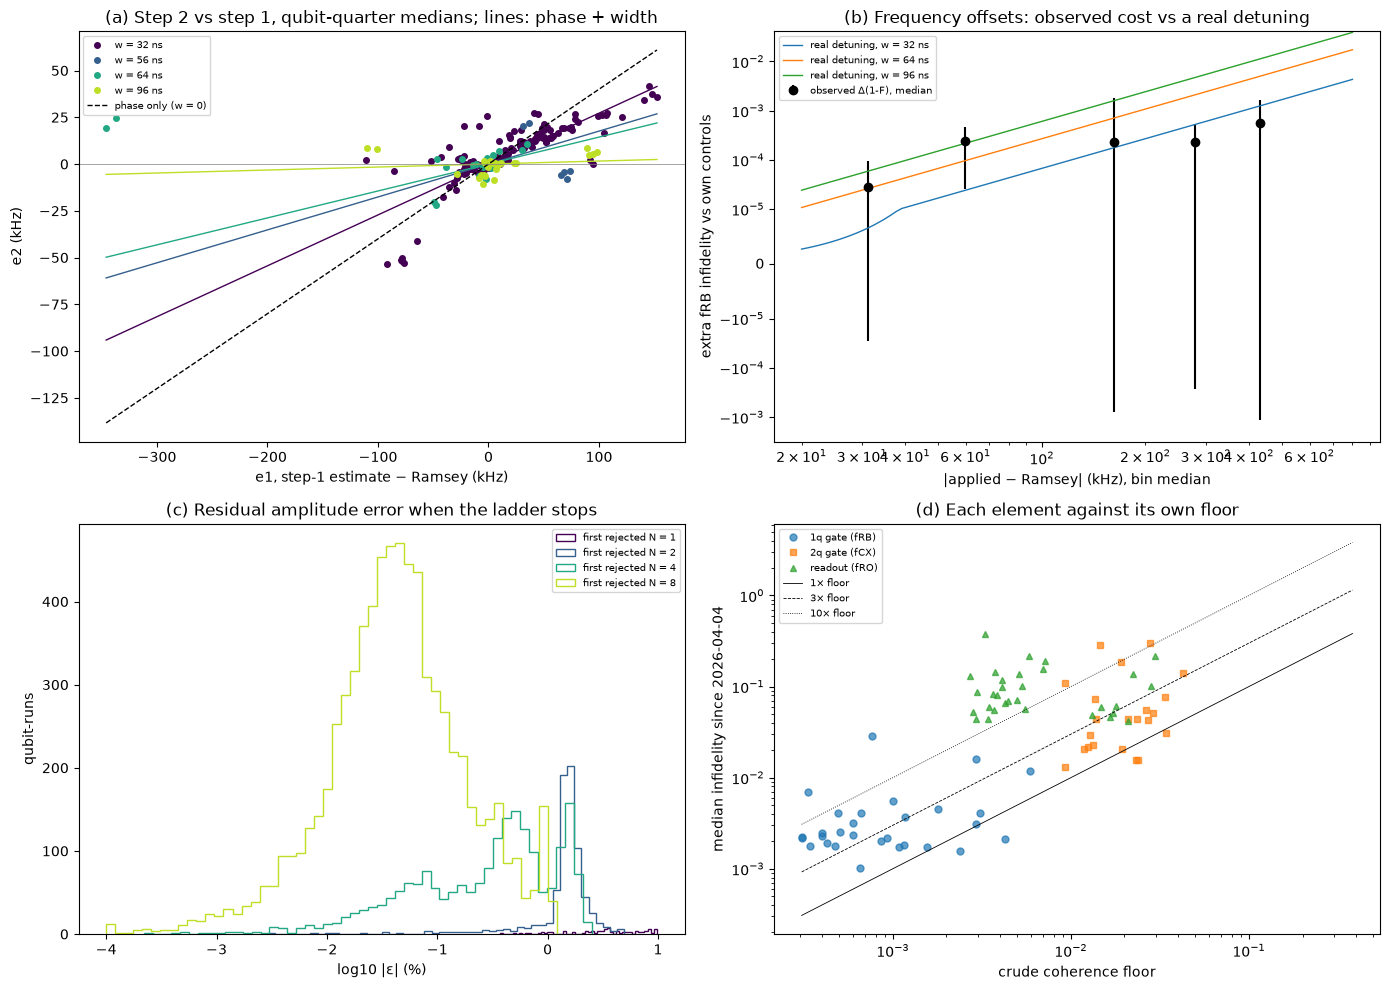

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) Step 2 against step 1 on qubit-quarter medians, with the phase + width line per width class
a = ax[0, 0]
cm2 = (
    M.dropna(subset=["e2"])
    .groupby(["w_ns", "qubit", "quarter"])
    .agg(n=("e1", "size"), e1=("e1", "median"), e2=("e2", "median"))
    .reset_index()
)
cm2 = cm2[cm2["n"] >= MIN_RUNS]
xx = np.linspace(cm2["e1"].min(), cm2["e1"].max(), 2) / 1e3
colours = plt.cm.viridis(np.linspace(0, 0.9, cm2["w_ns"].nunique()))
for (w, c), col in zip(cm2.groupby("w_ns"), colours):
    a.plot(c["e1"] / 1e3, c["e2"] / 1e3, "o", ms=4, color=col, label=f"w = {w} ns")
    a.plot(xx, xx * (TAU[1] - w * 1e-9) / TAU[2], "-", color=col, lw=1)
a.plot(xx, xx * TAU[1] / TAU[2], "k--", lw=1, label="phase only (w = 0)")
a.axhline(0, color="grey", lw=0.5)
a.set(
    xlabel="e1, step-1 estimate − Ramsey (kHz)",
    ylabel="e2 (kHz)",
    title="(a) Step 2 vs step 1, qubit-quarter medians; lines: phase + width",
)
a.legend(fontsize=7)

# (b) Observed cost of frequency offsets against the real-detuning bound for three widths
a = ax[0, 1]
s = PHYS.set_index("bin").reindex(LABELS)
a.errorbar(
    s["e_med_kHz"],
    s["dr_med"],
    yerr=[s["dr_med"] - s["dr_lo"], s["dr_hi"] - s["dr_med"]],
    fmt="o",
    color="k",
    label="observed Δ(1-F), median",
)
ee = np.geomspace(20, 800, 100)
for w in [32e-9, 64e-9, 96e-9]:
    a.plot(
        ee, (2 * np.pi * ee * 1e3 * w) ** 2 / 6, lw=1, label=f"real detuning, w = {w * 1e9:.0f} ns"
    )
a.set(
    xscale="log",
    yscale="symlog",
    xlabel="|applied − Ramsey| (kHz), bin median",
    ylabel="extra fRB infidelity vs own controls",
    title="(b) Frequency offsets: observed cost vs a real detuning",
)
a.set_yscale("symlog", linthresh=1e-5)
a.legend(fontsize=7)

# (c) Residual amplitude error when the ladder stops, by first rejected N
a = ax[1, 0]
for n, c in zip((1, 2, 4, 8), plt.cm.viridis(np.linspace(0, 0.9, 4))):
    x = AREJ[(AREJ["N"] == n) & AREJ["in_sweep"]]["eps"].abs() * 100
    if len(x):
        a.hist(
            np.log10(x.clip(lower=1e-4)),
            bins=50,
            histtype="step",
            color=c,
            label=f"first rejected N = {n}",
        )
a.set(
    xlabel="log10 |ε| (%)",
    ylabel="qubit-runs",
    title="(c) Residual amplitude error when the ladder stops",
)
a.legend(fontsize=7)

# (d) Each element's infidelity against its own coherence floor
a = ax[1, 1]
for (op, d), mk in zip(CTX.groupby("op"), ["o", "s", "^"]):
    a.loglog(d["floor"], d["x"], mk, ms=5, alpha=0.7, label=op)
lim = np.array([CTX[["floor", "x"]].min().min(), CTX[["floor", "x"]].max().max()])
for s_, ls in [(1, "-"), (3, "--"), (10, ":")]:
    a.plot(lim, s_ * lim, "k", ls=ls, lw=0.6, label=f"{s_}× floor")
a.set(
    xlabel="crude coherence floor",
    ylabel="median infidelity since 2026-04-04",
    title="(d) Each element against its own floor",
)
a.legend(fontsize=7)

fig.tight_layout()
fig.savefig(FIG / "d3a_ladders.png", dpi=130)
plt.show()

**Results.**

- **1q budget.** On 29 qubits, coherence explains a median 0.26 of the fRB infidelity. Frame and pulse phase explain 0.007 and the leftover amplitude error 0.001. The remaining 0.74 is not explained by any priced term.
- **Against the floors.** The median fRO is about 16 times its floor, the 1q gate about 4 times and the 2q gate about 2 times (0.043 against 0.021). So readout sits furthest above its coherence limit, and the 2q gates sit closest.
- **Failed fits.** 7 of 30 couplings have non-ok fCX in over half their runs. 22-18 has no kept value at all.

**Echo T2 or Ramsey T2\*.** The coherence term uses echo T2, and the echo removes slow frequency noise. A sequence of X/2 pulses has no echo, so slow noise also acts on it. DS1 has no long Ramsey experiment. Each calibrate_1q Ramsey fit gives a decay time $x_0$, but its trace is only 0.5 µs long. So single fits are noisy, and some come out negative. The next cell takes the median decay rate $1/x_0$ per qubit over the usable fits since 2026-04-04, with a bootstrap interval over runs. Its inverse is $T_2^*$.

The extra dephasing that the echo removes is

$$\Gamma_x = \max\left(\frac{1}{T_2^*} - \frac{1}{T_2},\ 0\right).$$

How much it adds per Clifford depends on how fast the noise is. Two limits bound it, with $t_c = \beta w$ the pulse time per Clifford.

- **Fast noise.** $\Gamma_x$ adds to the dephasing rate during every pulse. This adds $t_c\,\Gamma_x/3$ and is an upper bound. On a qubit where it exceeds the measured fRB infidelity, the noise can't be fast.
- **Slow noise.** The detuning stays fixed over a sequence, with a spread set by a Gaussian decay at rate $\Gamma_x$. This adds about $(t_c\,\Gamma_x)^2/3$ and is a lower bound.

In [13]:
# Ramsey runs since the cooldown, outside incidents and settling, with a usable fit
RS = R[(R["start"] >= COOL) & ~np.asarray(periods.within(R["start"], *EXCL))].copy()
usable = (
    (RS["chi_rel"] <= POOR_FIT)
    & RS["A_rel"].between(LOW_CONTRAST, 1 / LOW_CONTRAST)
    & np.isfinite(RS["x0"])
    & (RS["x0"] != 0)
)
print(f"Ramsey rows since {COOL:%Y-%m-%d}: {len(RS):,}; usable fits: {usable.sum():,}")
RS = RS[usable]

# Decay rate per run. A 0.5 us trace barely decays, so single fits are noisy and some are
# negative. The median rate per qubit keeps them all.
RS["rate"] = 1 / RS["x0"]  # 1/s
print(
    "per-run decay time x0 (us), quantiles:",
    (RS["x0"] * 1e6).quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_dict(),
)


def median_ci(s):
    """Median of s, with a 95% bootstrap interval over runs."""
    x = s.to_numpy()
    b = np.median(x[rng.integers(0, len(x), (N_BOOT, len(x)))], axis=1)
    return pd.Series(
        {"runs": len(x), "rate": np.median(x), "lo": np.quantile(b, 0.025), "hi": np.quantile(b, 0.975)}
    )


T2S = RS.groupby("qubit")["rate"].apply(median_ci).unstack()
T2S = T2S.join(Q1[["fRB", "T1", "T2", "w_ns", "coherence"]], how="inner")
T2S["T2star"] = 1e6 / T2S["rate"]  # us
T2S["T2star_lo"] = 1e6 / T2S["hi"]
T2S["T2star_hi"] = 1e6 / T2S["lo"]

# Extra dephasing that the echo removes: Ramsey rate minus echo rate (T1 cancels)
T2S["extra"] = (T2S["rate"] - 1 / (T2S["T2"] * 1e-6)).clip(lower=0)  # 1/s
t_c = BETA * T2S["w_ns"] * 1e-9  # pulse time per Clifford, s

# Fast noise: an extra dephasing rate during every pulse (upper bound)
T2S["fast"] = t_c * T2S["extra"] / 3
# Slow noise: a detuning fixed over a sequence (lower bound)
T2S["slow"] = (t_c * T2S["extra"]) ** 2 / 3

# Coherence share of the fRB infidelity: echo only (as above), and with each reading
T2S["share_echo"] = T2S["coherence"] / T2S["fRB"]
T2S["share_fast"] = (T2S["coherence"] + T2S["fast"]) / T2S["fRB"]
T2S["share_slow"] = (T2S["coherence"] + T2S["slow"]) / T2S["fRB"]

print(
    f"\nqubits {len(T2S)}; usable runs per qubit, median {T2S['runs'].median():.0f}; "
    f"T2* below echo T2 on {(T2S['T2star'] < T2S['T2']).sum()}; "
    f"T2* above 2 T1 on {(T2S['T2star'] > 2 * T2S['T1']).sum()}"
)
display(
    T2S[["T1", "T2", "T2star", "share_echo", "share_fast", "share_slow"]]
    .median()
    .to_frame("median over qubits")
    .T.round(3)
)
print(
    "qubits where the fast reading alone exceeds the measured fRB infidelity:",
    int((T2S["share_fast"] > 1).sum()),
)
display(
    T2S.sort_values("share_fast", ascending=False)[
        ["runs", "T1", "T2", "T2star", "T2star_lo", "T2star_hi", "fRB", "share_echo", "share_fast", "share_slow"]
    ]
    .head(10)
    .round(3)
)

Ramsey rows since 2026-04-04: 7,710; usable fits: 7,346
per-run decay time x0 (us), quantiles: {0.1: 1.5, 0.25: 3.6, 0.5: 9.5, 0.75: 26.7, 0.9: 4015727.2}

qubits 27; usable runs per qubit, median 257; T2* below echo T2 on 24; T2* above 2 T1 on 0


,T1,T2,T2star,share_echo,share_fast,share_slow
median over qubits,67.96,57.829,10.641,0.256,0.897,0.258


qubits where the fast reading alone exceeds the measured fRB infidelity: 12


,runs,T1,T2,T2star,T2star_lo,T2star_hi,fRB,share_echo,share_fast,share_slow
qubit,,,,,,,,,,
17,257.0,73.389,52.146,2.361,2.231,2.536,0.002,0.419,6.941,0.700
26,257.0,62.016,53.782,3.624,3.524,3.729,0.002,0.619,6.595,0.806
19,257.0,90.623,93.549,6.705,6.362,7.261,0.001,0.642,6.125,0.734
31,257.0,78.302,15.764,4.792,4.461,5.800,0.002,1.985,6.115,2.095
21,257.0,65.814,6.911,1.110,0.968,2.036,0.004,0.747,4.457,0.917
6,257.0,43.117,13.055,1.826,1.714,2.297,0.005,0.395,2.508,0.456
35,255.0,59.329,63.278,2.314,2.126,2.615,0.004,0.119,2.166,0.171
33,257.0,76.300,116.044,5.778,5.381,6.544,0.002,0.142,1.685,0.158
1,257.0,86.986,44.186,14.247,13.550,18.318,0.002,0.624,1.669,0.630


**Results.**

- **Single fits say little.** 7,346 of the 7,710 Ramsey fits since 2026-04-04 are usable. Their decay time has a median of 9.5 µs and quartiles of 3.6 and 26.7 µs.
- **T2\*.** On 27 qubits, the median T2\* is 10.6 µs, against 58 µs for echo T2. T2\* is below echo T2 on 24 of them.
- **Fast noise is ruled out on 12 qubits.** On those, the fast reading alone predicts more infidelity than fRB measures. So the extra dephasing is mostly slow.
- **The budget barely moves.** The slow reading raises the median coherence share from 0.256 to 0.258. The fast reading gives 0.90, but it is an upper bound and fails on 12 qubits. Noise between the two limits, such as 1/f noise, can't be ruled out on the other qubits.

## 7. Recalibration cadence: what skipping runs would cost

calibrate_1q runs about twice a day. If it ran less often, the drive frequency and X/2 amplitude in use would be older when a circuit runs. The benchmarks can't measure this, because they run just after a calibration, so this section prices it with the cost terms from sections 4 and 5.

For each qubit, take the drive frequencies and X/2 amplitudes that calibrate_1q wrote to DS2. Skipping $k - 1$ runs leaves the value from write $i$ in use when write $i + k$ would have replaced it. So the offset at lag $k$ is the frequency change $e_k$ between the two writes, and the relative amplitude change

$$\varepsilon_k = \frac{a_{i+k}}{a_i} - 1.$$

Here $a$ is the X/2 amp times the drive scale. The amp alone mostly cancels changes in the drive scale ([Phase 01, B3](../../docs/phases/01_eda.md#b3-ds1-measurements)), so its own changes are not errors.

A detuning $e$ adds about $(2\pi e w)^2/6$ per Clifford, with $w$ the X/2 width (a lower bound, section 4). An amplitude error $\varepsilon$ adds about

$$\frac{\beta\,\big((\pi/2)\,\varepsilon\big)^2}{6},$$

with $\beta = 1.9$ X/2 pulses per Clifford (section 5).

Each write has its own measurement error, so the cost at lag 1 is set by the routine's noise, not by drift. The cost of skipping is the excess over lag 1. Pairs that span a STOP event (break, outage, thermal cycle or incident) or sit in settling are left out, so the cost is that of normal operation.

In [14]:
# Snapshots written by calibrate_1q runs
rm = load_run_map()
cal_snaps = set(rm.loc[rm["routine"] == "calibrate_1q", "snap_after"].dropna())

# One long table of every DS2 value of the three fields
parts = []
for name, pat in PATHS.items():
    x = v[v["path"].str.fullmatch(pat.replace("(\\d+)", "\\d+"))]
    parts.append(
        pd.DataFrame(
            {
                "field": name,
                "qubit": x["path"].str.extract(pat)[0].astype(int),
                "t": x["valid_from_ts"],
                "y": x["value_float"].fillna(x["value_int"]).astype(float),
            }
        )
    )
dv = pd.concat(parts, ignore_index=True).dropna(subset=["y"])
dv["cal"] = dv["t"].isin(cal_snaps)


def field_summary(g):
    """Value count, span, and the share of changes written by a calibrate_1q run."""
    return pd.Series(
        {
            "values": len(g),
            "qubits": g["qubit"].nunique(),
            "first": g["t"].min(),
            "last": g["t"].max(),
            "cal_share_of_changes": g.loc[g["change"], "cal"].mean(),
        }
    )


# How many DS2 changes (after each qubit's first value) calibrate_1q wrote
first_t = dv.groupby(["field", "qubit"])["t"].transform("min")
print(
    "DS2 values per field, and the share of changes (after the first value) written by a calibrate_1q run:"
)
display(
    dv.assign(change=dv["t"] > first_t).groupby("field").apply(field_summary, include_groups=False)
)

# DS2 holds a row per value change, so the deployed value at each calibrate_1q write
# is the last value at or before it
ct = pd.DataFrame({"t": sorted(cal_snaps)}).astype({"t": "datetime64[ns]"})
per_qubit = []
for q in sorted(dv["qubit"].unique()):
    s = ct.assign(qubit=q)
    for f in PATHS:
        fv = (
            dv[(dv["qubit"] == q) & (dv["field"] == f)]
            .sort_values("t")[["t", "y"]]
            .rename(columns={"y": f})
        )
        s = pd.merge_asof(s, fv.astype({"t": "datetime64[ns]"}), on="t", direction="backward")
    per_qubit.append(s)

# Qubit-writes with all three fields, from the first frequency value on
CW = pd.concat(per_qubit, ignore_index=True).dropna(subset=["freq", "amp", "width"])
CW = CW[CW["t"] >= dv.loc[dv["field"] == "freq", "t"].min()]

# The hardware multiplies the X/2 amp by the drive scale, and calibrate_1q's amp
# mostly cancels changes in the scale (B3c), so the physical setting is amp x scale
CW["amp_x_scale"] = CW["amp"] * series.scale_at(CW["t"], CW["qubit"], series.drive_scale())
print(
    f"calibrate_1q writes: {len(ct):,} ({ct['t'].min():%Y-%m-%d} to {ct['t'].max():%Y-%m-%d}); "
    f"qubit-writes with all three fields: {len(CW):,}, without a drive scale: "
    f"{CW['amp_x_scale'].isna().sum():,}"
)
CW = CW.dropna(subset=["amp_x_scale"])
print(
    "X/2 width (ns), per-qubit-write quantiles:",
    (CW["width"] * 1e9).quantile([0, 0.5, 1]).round(3).to_dict(),
)

DS2 values per field, and the share of changes (after the first value) written by a calibrate_1q run:


,values,qubits,first,last,cal_share_of_changes
field,,,,,
amp,34369,32,2025-01-01 08:00:13,2026-08-18 09:02:58,0.994088
freq,33176,32,2025-01-01 08:00:13,2026-08-18 09:02:58,0.993061
width,37,32,2025-01-01 08:00:13,2026-03-26 09:25:08,0.000000


calibrate_1q writes: 1,121 (2025-01-01 to 2026-08-18); qubit-writes with all three fields: 35,872, without a drive scale: 0
X/2 width (ns), per-qubit-write quantiles: {0.0: 32.0, 0.5: 32.0, 1.0: 96.0}


### 7.1 Offsets and cost by lag

For each qubit and lag $k$ this takes every pair of writes $k$ apart. A pair is left out if it spans a STOP event or either end is in settling.

Two kinds of change are counted apart and not priced, because they aren't drift and the small-angle cost terms no longer hold. A frequency change above 2 MHz is a failed Ramsey fit (section 4). An amplitude change above 10% is wider than the $N = 1$ window, so no single ladder run can produce it.

Per lag the table gives the median time between the writes, the median $|e_k|$ and $|\varepsilon_k|$, and the cost both as a median and as a mean over pairs. The mean is what a circuit pays on average. Its interval comes from a bootstrap over qubits.

In [15]:
# STOP event times, and a settling flag per qubit-write
EV = series.register_events()
stops = np.sort(EV.loc[EV["type"].isin(STOP), "at"].to_numpy("datetime64[ns]"))
CW = CW.sort_values(["qubit", "t"], ignore_index=True)
CW["settling"] = np.asarray(periods.within(CW["t"], *periods.SETTLING))

# Every pair of writes k apart per qubit, without STOP spans or settling at either end
rows = []
for k_lag in LAGS:
    g = CW.groupby("qubit")
    p = pd.DataFrame(
        {
            "qubit": CW["qubit"],
            "t0": CW["t"],
            "t1": g["t"].shift(-k_lag),
            "f0": CW["freq"],
            "f1": g["freq"].shift(-k_lag),
            "a0": CW["amp_x_scale"],
            "a1": g["amp_x_scale"].shift(-k_lag),
            "w": CW["width"],
            "s0": CW["settling"],
            "s1": g["settling"].shift(-k_lag),
        }
    ).dropna(subset=["t1"])

    # A pair spans a STOP event if more events lie before t1 than before t0
    n_stops_t1 = np.searchsorted(stops, p["t1"].to_numpy("datetime64[ns]"), "right")
    n_stops_t0 = np.searchsorted(stops, p["t0"].to_numpy("datetime64[ns]"), "right")
    span = n_stops_t1 > n_stops_t0
    p = p[~span & ~p["s0"] & ~p["s1"].astype(bool)].assign(lag=k_lag)
    rows.append(p)
PR = pd.concat(rows, ignore_index=True)

# Offsets, and the cost each would add per Clifford
PR["e_khz"] = (PR["f1"] - PR["f0"]) / 1e3
PR["eps"] = PR["a1"] / PR["a0"] - 1
PR["cost_freq"] = (2 * np.pi * PR["e_khz"] * 1e3 * PR["w"]) ** 2 / 6
PR["cost_amp"] = BETA * ((np.pi / 2) * PR["eps"]) ** 2 / 6
PR["cost"] = PR["cost_freq"] + PR["cost_amp"]
PR["hours"] = (PR["t1"] - PR["t0"]) / pd.Timedelta("1h")

# Changes beyond either cut are counted apart, not priced
PR["beyond_freq"] = PR["e_khz"].abs() > CUT_KHZ
PR["beyond_amp"] = PR["eps"].abs() > AMP_CUT
PR["beyond"] = PR["beyond_freq"] | PR["beyond_amp"]
print(
    f"cost at the cuts: frequency (2π·{CUT_KHZ} kHz·32 ns)²/6 = "
    f"{(2 * np.pi * CUT_KHZ * 1e3 * 32e-9) ** 2 / 6:.3g}, amplitude β((π/2)·{AMP_CUT})²/6 = "
    f"{BETA * ((np.pi / 2) * AMP_CUT) ** 2 / 6:.3g} per Clifford"
)
print("pairs beyond the cuts per lag (share) and the qubits they sit on:")
top_qubits = (
    PR[PR["beyond"]]
    .groupby("lag")["qubit"]
    .agg(lambda s: s.value_counts().head(5).to_dict())
    .rename("top_qubits")
)
display(
    PR.groupby("lag")
    .agg(
        beyond_freq=("beyond_freq", "sum"),
        beyond_amp=("beyond_amp", "sum"),
        share=("beyond", "mean"),
    )
    .join(top_qubits)
)
PR = PR[~PR["beyond"]]

# Mean cost per qubit and lag, with a bootstrap over qubits for the chip mean
rng_lag = np.random.default_rng(0)
qs = PR.groupby(["lag", "qubit"])[["cost_freq", "cost_amp", "cost"]].mean()
boot = {}
for k_lag, g in qs.groupby(level="lag"):
    vals = g.to_numpy()
    b = np.array([vals[rng_lag.integers(0, len(vals), len(vals))].mean(0) for _ in range(N_BOOT)])
    lo = dict(zip(["freq_lo", "amp_lo", "cost_lo"], np.quantile(b, 0.025, axis=0)))
    hi = dict(zip(["freq_hi", "amp_hi", "cost_hi"], np.quantile(b, 0.975, axis=0)))
    boot[k_lag] = lo | hi

# Per lag: pair counts, typical offsets, median and mean cost
LT = PR.groupby("lag").agg(
    pairs=("cost", "size"),
    qubits=("qubit", "nunique"),
    hours_median=("hours", "median"),
    abs_e_khz_median=("e_khz", lambda s: s.abs().median()),
    abs_eps_median=("eps", lambda s: s.abs().median()),
    cost_median=("cost", "median"),
    cost_freq=("cost_freq", "mean"),
    cost_amp=("cost_amp", "mean"),
    cost=("cost", "mean"),
)
LT = LT.join(pd.DataFrame(boot).T)

# How much of the mean sits in the largest 1% of pairs
LT["cost_mean_without_top1pct"] = PR.groupby("lag")["cost"].apply(
    lambda s: s[s <= s.quantile(0.99)].mean()
)
LT["excess_over_lag1"] = LT["cost"] - LT.loc[1, "cost"]
print(
    "offset between calibrate_1q writes k apart (STOP spans, settling and pairs beyond the cuts out) "
    "and the cost it would add per Clifford:"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(LT)

cost at the cuts: frequency (2π·2000 kHz·32 ns)²/6 = 0.027, amplitude β((π/2)·0.1)²/6 = 0.00781 per Clifford
pairs beyond the cuts per lag (share) and the qubits they sit on:


,beyond_freq,beyond_amp,share,top_qubits
lag,,,,
1,223,423,0.012311,"{23: 126, 19: 44, 16: 27, 11: 20, 21: 17}"
2,230,406,0.012046,"{23: 135, 19: 43, 16: 28, 11: 20, 21: 13}"
3,211,396,0.011881,"{23: 143, 19: 41, 16: 28, 11: 25, 21: 15}"
4,196,381,0.011521,"{23: 148, 19: 39, 16: 28, 11: 25, 21: 15}"
6,128,314,0.009764,"{23: 150, 19: 36, 16: 26, 11: 23, 21: 16}"
8,91,273,0.008696,"{23: 148, 19: 38, 16: 26, 11: 24, 21: 14}"
14,85,257,0.008701,"{23: 132, 19: 37, 16: 26, 11: 24, 1: 15}"
28,76,215,0.008220,"{23: 106, 19: 38, 16: 24, 11: 17, 1: 13}"


offset between calibrate_1q writes k apart (STOP spans, settling and pairs beyond the cuts out) and the cost it would add per Clifford:


,pairs,qubits,hours_median,abs_e_khz_median,abs_eps_median,cost_median,cost_freq,cost_amp,cost,freq_lo,amp_lo,cost_lo,freq_hi,amp_hi,cost_hi,cost_mean_without_top1pct,excess_over_lag1
lag,,,,,,,,,,,,,,,,,
1,34419,32,12,3.98,0.00106,1.87e-06,2.22e-05,3.24e-05,5.46e-05,1.23e-05,1.75e-05,3.38e-05,3.45e-05,4.93e-05,7.8e-05,2.65e-05,0
2,33954,32,24,4.35,0.00103,2.15e-06,2.79e-05,3.6e-05,6.38e-05,1.52e-05,2.3e-05,4.37e-05,4.48e-05,5.24e-05,8.74e-05,3.41e-05,9.25e-06
3,33517,32,36.1,4.63,0.0015,3.59e-06,3.02e-05,4.14e-05,7.16e-05,1.71e-05,2.58e-05,4.89e-05,4.63e-05,6.17e-05,9.87e-05,3.86e-05,1.7e-05
4,33118,32,48,4.69,0.00156,4.01e-06,3.3e-05,4.26e-05,7.56e-05,1.84e-05,2.61e-05,4.9e-05,5.44e-05,6.47e-05,0.000107,4.04e-05,2.1e-05
6,32353,32,72,4.96,0.00185,5.07e-06,3.53e-05,4.37e-05,7.9e-05,1.95e-05,2.55e-05,5.35e-05,5.6e-05,6.74e-05,0.000111,4.25e-05,2.44e-05
8,31690,32,96,5.24,0.00204,5.88e-06,3.78e-05,4.37e-05,8.15e-05,2.13e-05,2.47e-05,5.56e-05,5.78e-05,6.74e-05,0.000112,4.41e-05,2.69e-05
14,29850,32,168,5.74,0.00213,6.57e-06,4.03e-05,4.32e-05,8.35e-05,2.32e-05,2.47e-05,5.88e-05,6.1e-05,6.8e-05,0.000112,4.61e-05,2.89e-05
28,26183,32,336,6.59,0.00227,7.68e-06,3.43e-05,4.14e-05,7.57e-05,2.13e-05,2.29e-05,5.06e-05,4.99e-05,6.71e-05,0.000101,4.57e-05,2.11e-05


**Results.**

- **Changes beyond the cuts.** 1.2% of pairs at lag 1 and 0.8% at lag 28 have a frequency change above 2 MHz or an amplitude change above 10%. Q23 holds the most at every lag. These are not priced below.
- **Offsets grow slowly.** The median $|e_k|$ grows from 4.0 kHz at lag 1 (12 h) to 6.6 kHz at lag 28 (336 h), and the median $|\varepsilon_k|$ from 0.11% to 0.23%.
- **Cost.** The mean cost is 5.5e-05 per Clifford at lag 1, with an interval from 3.4e-05 to 7.8e-05. It peaks at 8.4e-05 at lag 14 and is 7.6e-05 at lag 28, so the excess over lag 1 is at most 2.9e-05. The intervals at lag 1 and lag 14 overlap.
- **A few pairs carry the mean.** Without the top 1% of pairs the mean is about half (2.7e-05 at lag 1). The amplitude and frequency terms are about the same size.

### 7.2 Against the chip's 1q infidelity

This sets the same costs next to the kept fRB infidelity over the same span, with incidents and settling left out. The excess over lag 1 is shown as a share of two references: the chip median and the median of the per-qubit medians. Then the same share is computed per qubit at the longest lag that still has 25 or more qubits, to see whether a few qubits carry the cost.

kept fRB rows 13,091 on 32 qubits, 2025-01-01 to 2026-08-16; {'chip median': '0.0024', 'median of qubit medians': '0.00216'}


,excess / chip median,excess / median of qubit medians,cost / chip median
lag,,,
1,0,0,0.0227
2,0.00385,0.00428,0.0265
3,0.00708,0.00789,0.0298
4,0.00874,0.00974,0.0314
6,0.0102,0.0113,0.0328
8,0.0112,0.0125,0.0339
14,0.012,0.0134,0.0347
28,0.00878,0.00978,0.0315



per qubit at lag 28 (median 336 h): excess over lag 1 as a share of the qubit's median fRB infidelity; quantiles: {0.1: 0.0006, 0.5: 0.0051, 0.9: 0.0255}


,excess,fRB_median,share
qubit,,,
31,4.51e-05,0.000855,0.0527
25,8.03e-05,0.00198,0.0405
11,8.87e-05,0.00234,0.038
21,4.72e-05,0.00182,0.026
7,3.58e-05,0.00167,0.0215
15,7.84e-05,0.00385,0.0203
19,1.95e-05,0.00189,0.0103
30,1.33e-05,0.00129,0.0103


saved docs/figures/hypotheses/d3a_recal_cadence.png


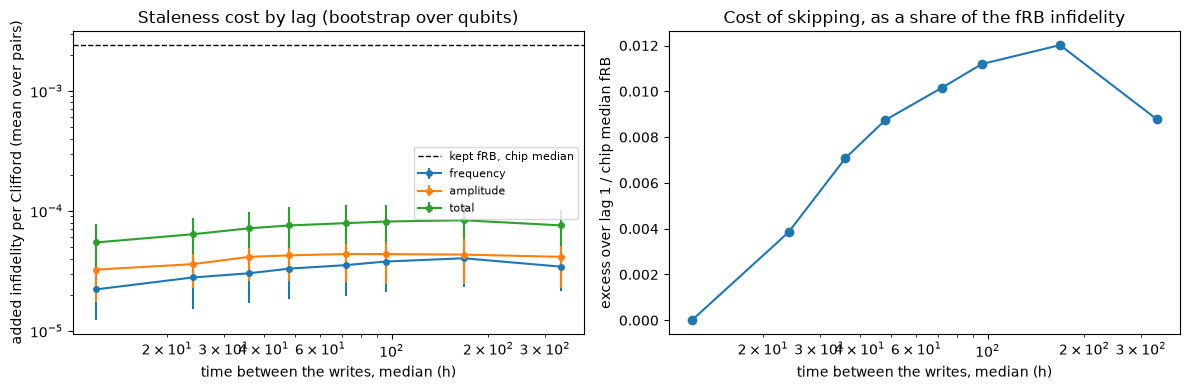

In [16]:
# Kept fRB on qubits over the span of the writes, without settling and incidents
rb = kept[
    (kept["metric"] == "fRB")
    & kept["element"].str.fullmatch(r"\d+")
    & (kept["t"] >= CW["t"].min())
    & (kept["t"] <= CW["t"].max())
]
rb = rb[
    ~np.asarray(periods.within(rb["t"], *periods.SETTLING))
    & ~np.asarray(periods.within(rb["t"], *[i.period for i in periods.INCIDENTS]))
]

# Two chip references: the chip median and the median of the per-qubit medians
per_q = rb.groupby("element")["x"].median()
refs = {"chip median": rb["x"].median(), "median of qubit medians": per_q.median()}
print(
    f"kept fRB rows {len(rb):,} on {rb['element'].nunique()} qubits, "
    f"{rb['t'].min():%Y-%m-%d} to {rb['t'].max():%Y-%m-%d};",
    {n: f"{v:.3g}" for n, v in refs.items()},
)

# Mean cost and excess over lag 1 as shares of the references
excess_shares = {f"excess / {n}": LT["excess_over_lag1"] / v for n, v in refs.items()}
SH = pd.DataFrame(excess_shares | {"cost / chip median": LT["cost"] / refs["chip median"]})
with pd.option_context("display.float_format", "{:.3g}".format):
    display(SH)

# Per qubit at the longest lag that keeps 25+ qubits: excess over lag 1 against its median fRB
kmax = max(k for k in LAGS if LT.loc[k, "qubits"] >= 25)
at_kmax = qs.xs(kmax, level="lag")
pq = at_kmax["cost"] - qs.xs(1, level="lag")["cost"].reindex(at_kmax.index)
frb_med = per_q.set_axis(per_q.index.astype(int)).reindex(pq.index)
pq = pd.DataFrame({"excess": pq, "fRB_median": frb_med})
pq["share"] = pq["excess"] / pq["fRB_median"]
print(
    f"\nper qubit at lag {kmax} (median {LT.loc[kmax, 'hours_median']:.3g} h): "
    "excess over lag 1 as a share of the qubit's median fRB infidelity;",
    "quantiles:",
    pq["share"].quantile([0.1, 0.5, 0.9]).round(4).to_dict(),
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pq.sort_values("share", ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Left: mean cost by lag for each term, against the chip median fRB
a = ax[0]
boot_prefix = {"cost_freq": "freq", "cost_amp": "amp", "cost": "cost"}
for c, lab in [("cost_freq", "frequency"), ("cost_amp", "amplitude"), ("cost", "total")]:
    lo, hi = boot_prefix[c] + "_lo", boot_prefix[c] + "_hi"
    a.errorbar(
        LT["hours_median"], LT[c], yerr=[LT[c] - LT[lo], LT[hi] - LT[c]], fmt="o-", ms=4, label=lab
    )
a.axhline(refs["chip median"], color="k", ls="--", lw=1, label="kept fRB, chip median")
a.set(
    xscale="log",
    yscale="log",
    xlabel="time between the writes, median (h)",
    ylabel="added infidelity per Clifford (mean over pairs)",
    title="Staleness cost by lag (bootstrap over qubits)",
)
a.legend(fontsize=8)

# Right: excess over lag 1 as a share of the chip median
a = ax[1]
a.plot(LT["hours_median"], SH["excess / chip median"], "o-")
a.set(
    xscale="log",
    xlabel="time between the writes, median (h)",
    ylabel="excess over lag 1 / chip median fRB",
    title="Cost of skipping, as a share of the fRB infidelity",
)

fig.tight_layout()
out = FIG / "d3a_recal_cadence.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- **Chip.** The excess over lag 1 is at most 1.2% of the chip median fRB infidelity, at lag 14 (one week). It is 0.4% at lag 2 (one day) and 0.9% at lag 28 (two weeks). Against the median of the qubit medians it is at most 1.3%.
- **Whole cost.** The full cost, lag 1 included, is 2.3% to 3.5% of the chip median. Most of it is the routine's own noise, which is there at any cadence.
- **Per qubit.** At lag 28 the excess is a median 0.5% of the qubit's own fRB infidelity, and 2.6% at the 90th percentile. Q31 has the largest share, 5.3%, mostly because its fRB infidelity is low.

## 8. Replaying a fix for the offset-carried rule

Offset-carried runs apply a value far from the qubit's frequency, while their own Ramsey value is close to it (section 2). This section replays fixed rules for the applied value on the same rows as section 2, and scores them against the same two references.

- **As run.** The value calibrate_1q applied.
- **Offset carried: Ramsey.** Offset-carried runs apply their own Ramsey value.
- **Any warning: Ramsey.** Every warned run applies its own Ramsey value.
- **Any warning: previous.** Every warned run keeps the value from before the run.

A rule keeps the applied value when the run has no Ramsey value. The scores are the number of errors above 200 kHz, the median error on warned runs and the rms error. The rms leaves out errors above 2 MHz, which mean a failed reference fit. A bootstrap over qubits gives an interval for the share of large errors that each rule removes.

The replay is exact for one run ahead. Each run measures the frequency again with its own Ramsey, so a different applied value doesn't change what the next run finds. Offsets don't cost 1q RB the way a real detuning would (section 4), so a better value helps the frame between gates, for example during idle time, more than the 1q gates. Errors on clean runs come from real frequency moves, and no fall-back rule can fix them.

In [17]:
# Four fixed rules for the value calibrate_1q applies
RPL_RULES = {
    "as run": lambda d: d["f_app"],
    "offset carried: Ramsey": lambda d: d["f_ramsey"].where(
        (d["cls"] == "offset carried") & d["f_ramsey"].notna(), d["f_app"]
    ),
    "any warning: Ramsey": lambda d: d["f_ramsey"].where(d["warn"] & d["f_ramsey"].notna(), d["f_app"]),
    "any warning: previous": lambda d: d["f_prev"].where(d["warn"], d["f_app"]),
}

# Same rows as section 2: outside incidents and settling
RPL = L[~L["excl"]].copy()
for name, rule in RPL_RULES.items():
    RPL[name] = rule(RPL)


def score(d, ref):
    """Errors of each rule against one reference."""
    rows = {}
    for name in RPL_RULES:
        e = (d[name] - d[ref]).abs()
        ok = e[e <= MAX_E]  # larger errors mean a failed reference fit
        rows[name] = {
            "rows": len(e),
            "warned median kHz": e[d["warn"]].median() / 1e3,
            "> 200 kHz": int((e > BIG).sum()),
            "rms kHz": np.sqrt((ok**2).mean()) / 1e3,
            "rms kHz, <= 200 kHz only": np.sqrt((ok[ok <= BIG] ** 2).mean()) / 1e3,
            "sq. error share > 200 kHz": (ok[ok > BIG] ** 2).sum() / (ok**2).sum(),
        }
    return pd.DataFrame(rows).T


for ref, label in [("ref_R", "next run's Ramsey"), ("ref_C", "next clean run's applied value")]:
    d = RPL[RPL[ref].notna()]
    print(f"\nagainst the {label}:")
    display(score(d, ref).round(3))

# Large errors left by each rule, by class and by era, against the next run's Ramsey
d = RPL[RPL["ref_R"].notna()]
is_big = pd.DataFrame({name: (d[name] - d["ref_R"]).abs() > BIG for name in RPL_RULES})
print("\napplied errors > 200 kHz against the next run's Ramsey, by class:")
display(is_big.groupby(d["cls"]).sum().reindex(order).dropna(how="all").astype(int))

by_era = is_big[["as run", "offset carried: Ramsey"]].groupby(d["era"]).sum()
by_era["removed share"] = 1 - by_era["offset carried: Ramsey"] / by_era["as run"]
print("\nthe same by era, as run against offset carried: Ramsey:")
display(by_era.round(3))

# Share of the large errors removed by each rule, with a 95% bootstrap interval over qubits
big_by_q = is_big.groupby(d["qubit"]).sum()
qs_ = big_by_q.index.to_numpy()
draws_ = []
for _ in range(N_BOOT):
    s = big_by_q.loc[rng.choice(qs_, len(qs_))].sum()
    draws_.append(1 - s / s["as run"])
draws_ = pd.DataFrame(draws_)
removed = 1 - big_by_q.sum() / big_by_q["as run"].sum()
print("\nshare of the > 200 kHz errors removed (next run's Ramsey), bootstrap over qubits:")
display(
    pd.DataFrame({"removed": removed, "lo": draws_.quantile(0.025), "hi": draws_.quantile(0.975)})
    .drop("as run")
    .round(3)
)


against the next run's Ramsey:


,rows,warned median kHz,> 200 kHz,rms kHz,"rms kHz, <= 200 kHz only",sq. error share > 200 kHz
as run,35867.0,115.513,867.0,63.719,25.535,0.843
offset carried: Ramsey,35867.0,25.939,329.0,48.764,24.861,0.742
any warning: Ramsey,35867.0,24.875,285.0,45.877,24.953,0.705
any warning: previous,35867.0,49.291,711.0,57.679,24.831,0.818



against the next clean run's applied value:


,rows,warned median kHz,> 200 kHz,rms kHz,"rms kHz, <= 200 kHz only",sq. error share > 200 kHz
as run,34141.0,195.563,224.0,29.500,17.015,0.669
offset carried: Ramsey,34141.0,75.275,134.0,25.169,16.226,0.586
any warning: Ramsey,34141.0,48.876,120.0,24.189,15.929,0.567
any warning: previous,34141.0,54.042,159.0,28.534,15.779,0.695



applied errors > 200 kHz against the next run's Ramsey, by class:


,as run,offset carried: Ramsey,any warning: Ramsey,any warning: previous
cls,,,,
clean,157,157,157,157
DRAG at zero,5,5,3,7
lost contrast,44,44,43,45
step-1 offset,37,37,37,48
offset carried,550,12,12,397
step-2 other,67,67,25,40
step-3,7,7,8,17



the same by era, as run against offset carried: Ramsey:


,as run,offset carried: Ramsey,removed share
era,,,
2024,82,7,0.915
2025-26Q1,258,154,0.403
2026Q2+,527,168,0.681



share of the > 200 kHz errors removed (next run's Ramsey), bootstrap over qubits:


,removed,lo,hi
offset carried: Ramsey,0.621,0.355,0.803
any warning: Ramsey,0.671,0.394,0.845
any warning: previous,0.180,0.094,0.300


**Results.**

- **The offset-carried fix removes most large errors.** Against the next run's Ramsey, it cuts the applied errors above 200 kHz from 867 to 329. That is a share of 0.62, with a 95% interval of 0.36 to 0.80 over qubits. Of the 550 large errors on offset-carried runs, 12 remain. The median error on warned runs falls from 116 to 26 kHz.
- **Ramsey on every warning gains a little more.** It leaves 285 large errors (0.67 removed). Most of the extra gain is on step-2 other runs (67 to 25). Keeping the previous value is worse and removes only 0.18.
- **The second reference agrees.** Against the next clean run's applied value, the large errors fall from 224 to 134 with the offset-carried fix and to 120 with Ramsey on every warning.
- **Only the tail changes.** The rms over errors up to 200 kHz stays near 25 kHz under every rule. The 157 large errors on clean runs remain, since they are real frequency moves.
- **By era.** The fix removes 0.68 of the large errors from 2026Q2 on, and 0.40 in 2025 to 2026Q1.

## Conclusion

**Verdict: holds.** Most frequency warnings come from the routine's own rules, and the error that the frequency and amplitude ladders leave behind costs the 1q gates little. Running calibrate_1q once a week instead of twice a day would add about 1% to the chip's 1q infidelity under the cost model. That leaves out the rare changes beyond the cuts. One rule change, applying the Ramsey value when step 2 undoes step 1, would remove most of the large frequency errors the routine applies.

| Result | Status |
|---|---|
| The payloads reproduce every frequency warning and every applied value (section 1). | Confirmed |
| 771 of the 1,948 frequency warnings are DRAG at zero and 673 are an offset carried from step 1. Offset-carried runs apply a value a median 301 kHz from the next run's Ramsey value, while their own Ramsey value is 23 kHz from it (section 2). | Holds |
| A pulse phase plus the X/2 width explains the step-2 bias better than a phase alone. The effective width matches DS2 for the 32 and 96 ns pulses. The 56 and 64 ns pulses come out near 100 ns, on few qubits (section 3). | Holds for 32 and 96 ns |
| The step-3 residuals can't tell the models apart, since a simulation under phase plus width also favours phase only. For the wide pulses, step 3 starts further from the Ramsey value than the model allows (section 3). | Model misses wide pulses at step 3 |
| The pulse phase is a stable property of each qubit. Qubit-quarter levels carry 0.64 of its variance (section 3). | Holds |
| Frequency offsets don't cost 1q RB the way a real detuning would. Large offsets come with worse conditions (more censored fRB and T1), and a per-pulse phase correction would remove under 1% of the fRB infidelity (section 4). | Holds, no correction needed |
| The amplitude ladder stops short because of its prediction window, not bad measurements. Its leftover error is predicted at 0.6% of the median fRB infidelity, or 2.7% with out-of-sweep estimates at their sweep edge. Runs that stop short have more censored fRB rows (section 5). | Holds |
| Coherence explains a median 0.26 of the 1q infidelity and the two calibration terms under 0.01, so 0.74 stays unexplained. Against their coherence floors, readout sits at about 16 times, the 1q gate at 4 and the 2q gate at 2 (section 6). | Holds |
| Ramsey T2\* is a median 10.6 µs, against 58 µs for echo T2. Fast noise at that rate would exceed the measured fRB infidelity on 12 of 27 qubits, so the extra dephasing is mostly slow. Read as slow noise, it raises the coherence share from 0.256 to 0.258 (section 6). | Holds, from 0.5 µs Ramsey traces |
| Skipping calibrate_1q runs adds at most 1.2% of the chip median fRB infidelity, at one week, and a median 0.5% per qubit at two weeks. About 1% of pairs change beyond the cuts and aren't priced (section 7). | Holds, cuts not priced |
| Applying the run's own Ramsey value on offset-carried runs removes 0.62 (0.36 to 0.80) of the applied errors above 200 kHz, and 538 of the 550 on that class. Ramsey on every warning removes 0.67, and keeping the previous value 0.18 (section 8). | Holds one run ahead; helps the frame, not 1q RB |

## Next steps

The 1q calibration error is small, so the next work moves to readout and the 2q gates. Readout sits furthest above its coherence floor, and several couplings fail their benchmark fit in most runs (section 6). Both are the planned d4 thread in [Phase 02](../../docs/phases/02_hypotheses.md#d4-error-by-operation).

- **Offset-carried fix.** Propose the section 8 rule for calibrate_1q: when step 2 undoes step 1, apply the Ramsey value. An A/B test on the device would confirm the replay, and show whether circuits with idle time gain from the better frame.
- **TODO: do the FineFrequency steps improve on Ramsey?** On clean runs, the applied value and the Ramsey value are equally close to the next run's Ramsey value (section 2). Both references used here are built from these same two estimates, so they can't decide this. That needs an independent frequency measurement.
- **d4a readout.** Split the readout error into decay during the measurement, thermal population and discrimination, and find what changed in 2026. DS2 holds a per-qubit readout confusion matrix (`error_mitigation.readout_mitigation.linear`) to start from.
- **d4b 2q couplings.** Set each coupling's fCX against its coherence floor (section 6) and list the couplings that are non-ok in most runs. Then check what they have in common, for example a qubit in a DRAG-zero episode ([D3b, section 2](d3b_drag_trap.ipynb)) or the cancel-scale history from calibrate_2q.